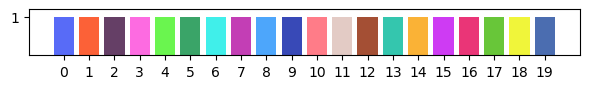

In [2]:
import glob, re, joblib
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.lines import Line2D
import string
import matplotlib.patches as mpatches
from Utils import colors_to_use
import math
#from matplotlib.backends.backend_pdf import PdfPages
from statannotations.Annotator import Annotator
from scipy.stats import mannwhitneyu
N = len(colors_to_use)

plt.figure(figsize=(6, 1))

plt.bar(
    range(N),
    [1] * N,
    color=colors_to_use
)

plt.xticks(range(N))
plt.yticks([1])
plt.ylim(0, 1.2)

plt.tight_layout()
plt.show()

# Stability

## k-NN

In [2]:
files = sorted(glob.glob("Datasets/*/XplainTDA/*/Stability/GRAE/kNN/quantile_bottleneck_metrics.csv"))

def parse_path(f):
    """Extract dataset and omic from Datasets/<dataset>/XplainTDA/<omic>/..."""
    parts = Path(f).parts
    i = parts.index("Datasets")
    return parts[i + 1], parts[i + 3]


def k_value(label):
    """Convert labels like 'k=50' to 50; use infinity for the full graph."""
    if label == "full":
        return np.inf
    m = re.search(r"k=(\d+)", str(label))
    return int(m.group(1)) if m else np.nan


dfs = []

for f in files:
    tmp = pd.read_csv(f)
    dataset, omic = parse_path(f)

    if "dataset" not in tmp.columns:
        tmp["dataset"] = dataset
    if "omic" not in tmp.columns:
        tmp["omic"] = omic

    tmp["source_file"] = f
    tmp["k1_numeric"] = tmp["label_a"].map(k_value)
    tmp["k2_numeric"] = tmp["label_b"].map(k_value)

    dfs.append(tmp)


if not dfs:
    raise FileNotFoundError(
        "No quantile bottleneck outputs found under "
        "Datasets/*/XplainTDA/*/Stability/GRAE/kNN/"
    )


df = pd.concat(dfs, ignore_index=True)

df0 = df[df["homology_dim"] == 0].copy()
df1 = df[df["homology_dim"] == 1].copy()
df2 = df[df["homology_dim"] == 2].copy()

df

,label_a,label_b,homology_dim,quantile,distance,distance_by_diameter,dataset,omic,source_file,k1_numeric,k2_numeric
0,full,k=5,0,0.50,6.566247e-10,4.425355e-10,BMMCMultiOme,GEX,Datasets/BMMCMultiOme/XplainTDA/GEX/Stability/...,inf,5
1,full,k=5,0,0.75,1.087094e-09,7.326522e-10,BMMCMultiOme,GEX,Datasets/BMMCMultiOme/XplainTDA/GEX/Stability/...,inf,5
2,full,k=5,0,0.90,1.716358e-09,1.156748e-09,BMMCMultiOme,GEX,Datasets/BMMCMultiOme/XplainTDA/GEX/Stability/...,inf,5
3,full,k=5,0,0.95,2.328805e-09,1.569510e-09,BMMCMultiOme,GEX,Datasets/BMMCMultiOme/XplainTDA/GEX/Stability/...,inf,5
4,full,k=5,0,0.99,3.698312e-09,2.492496e-09,BMMCMultiOme,GEX,Datasets/BMMCMultiOme/XplainTDA/GEX/Stability/...,inf,5
...,...,...,...,...,...,...,...,...,...,...,...
1075,k=1250,k=1250,2,0.75,0.000000e+00,0.000000e+00,PBMC,Peak,Datasets/PBMC/XplainTDA/Peak/Stability/GRAE/kN...,1250.0,1250
1076,k=1250,k=1250,2,0.90,0.000000e+00,0.000000e+00,PBMC,Peak,Datasets/PBMC/XplainTDA/Peak/Stability/GRAE/kN...,1250.0,1250
1077,k=1250,k=1250,2,0.95,0.000000e+00,0.000000e+00,PBMC,Peak,Datasets/PBMC/XplainTDA/Peak/Stability/GRAE/kN...,1250.0,1250
1078,k=1250,k=1250,2,0.99,0.000000e+00,0.000000e+00,PBMC,Peak,Datasets/PBMC/XplainTDA/Peak/Stability/GRAE/kN...,1250.0,1250


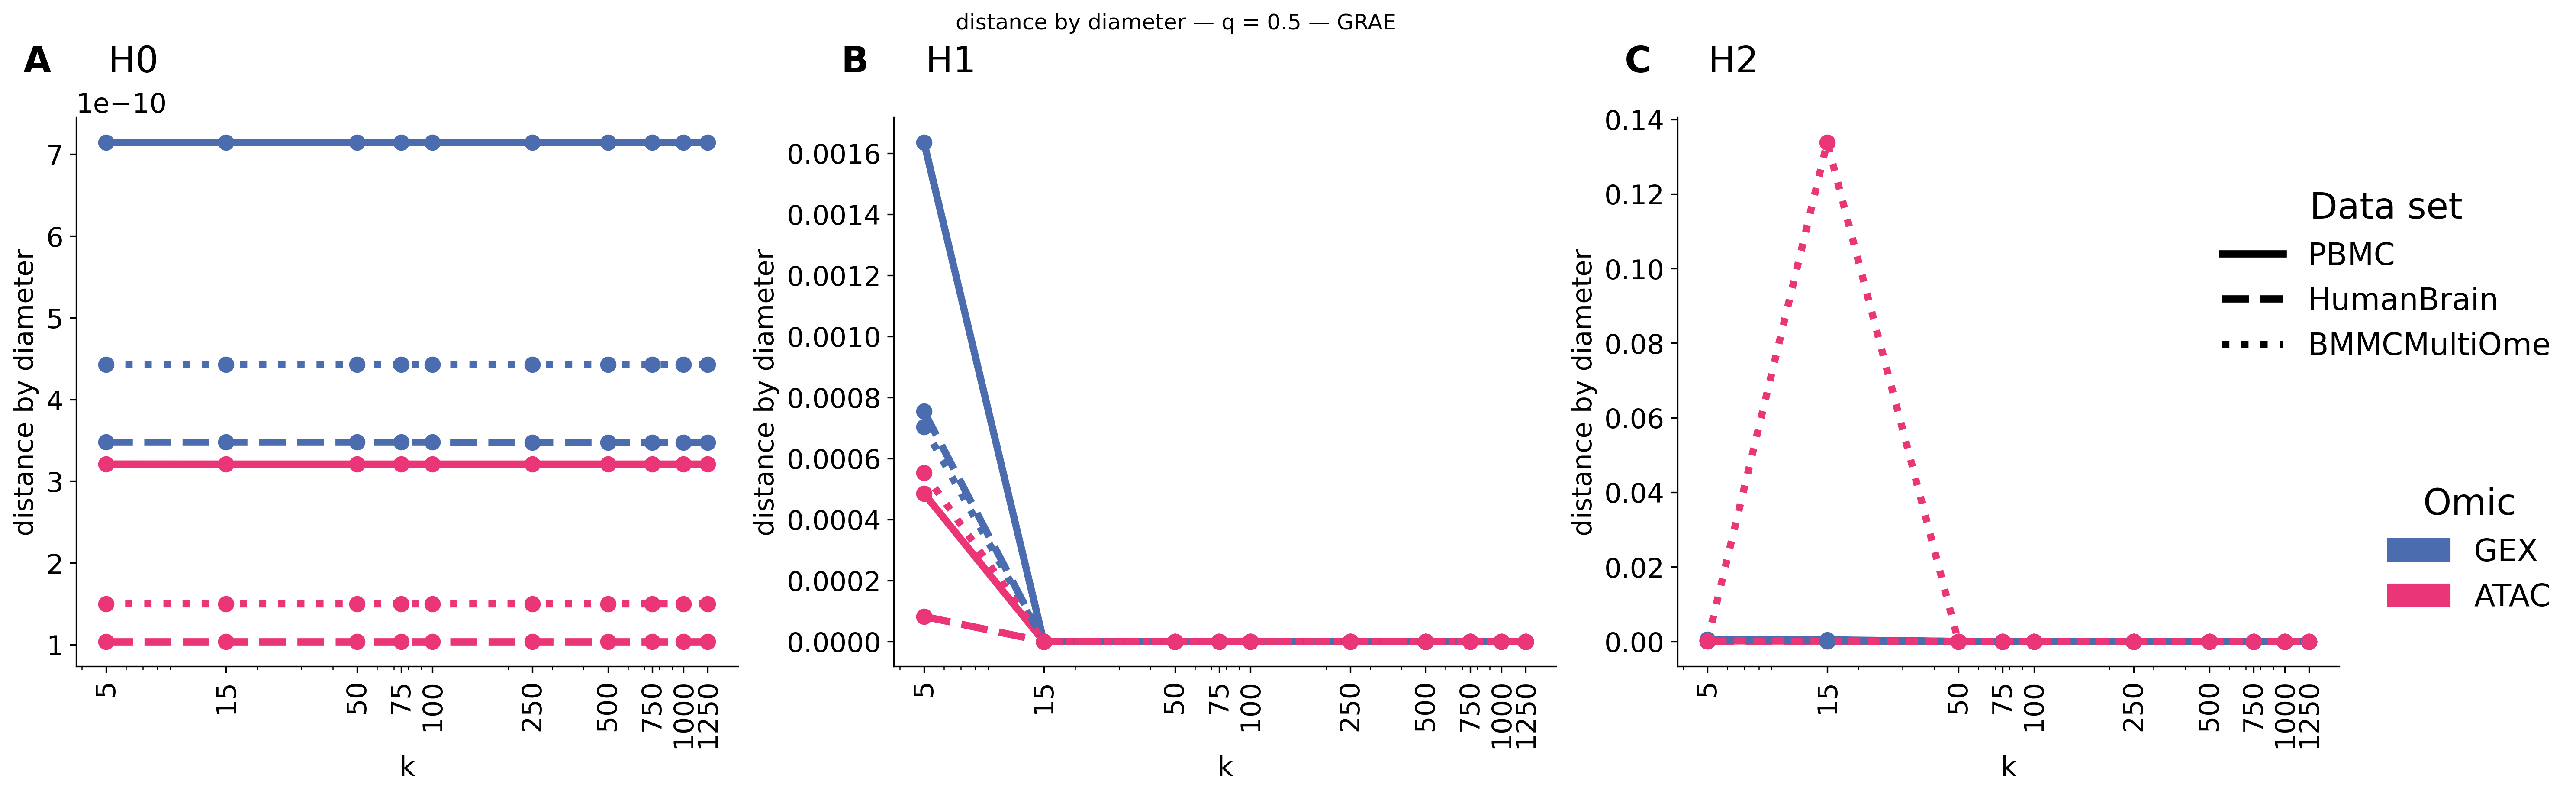

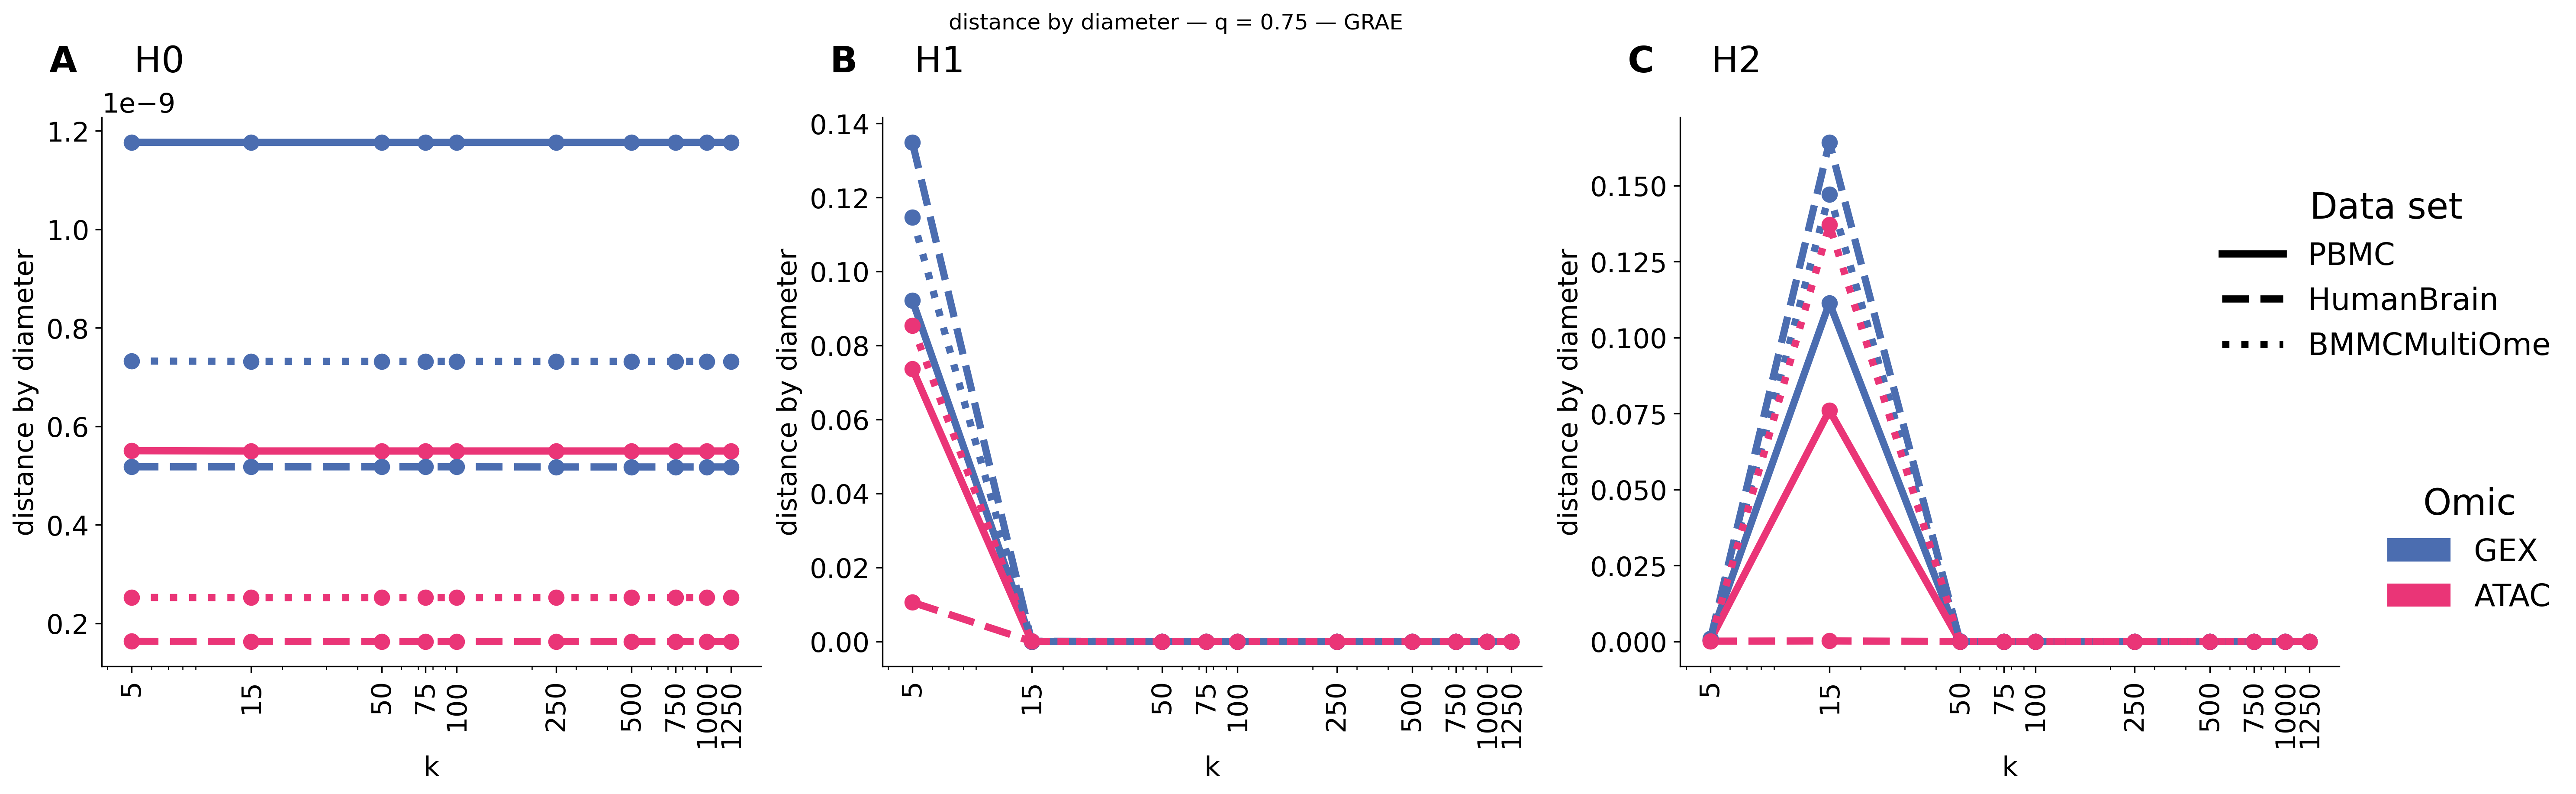

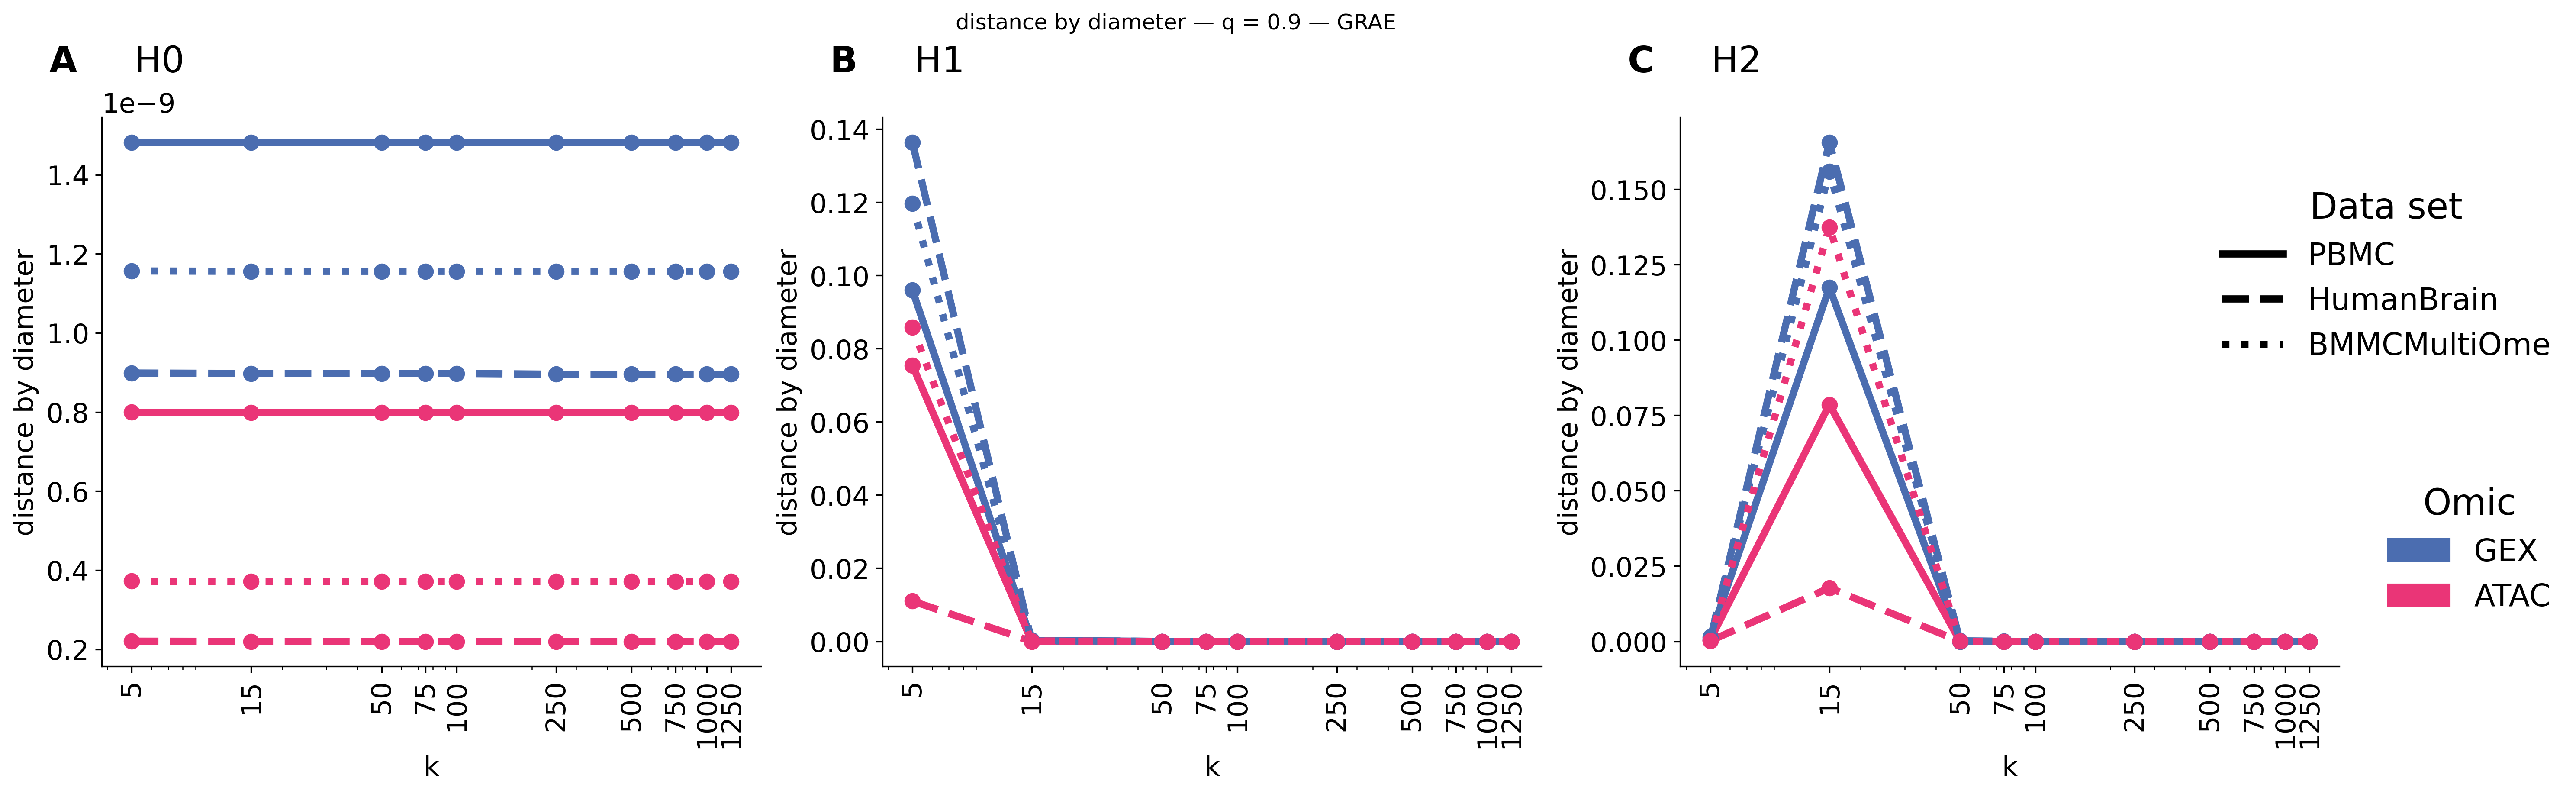

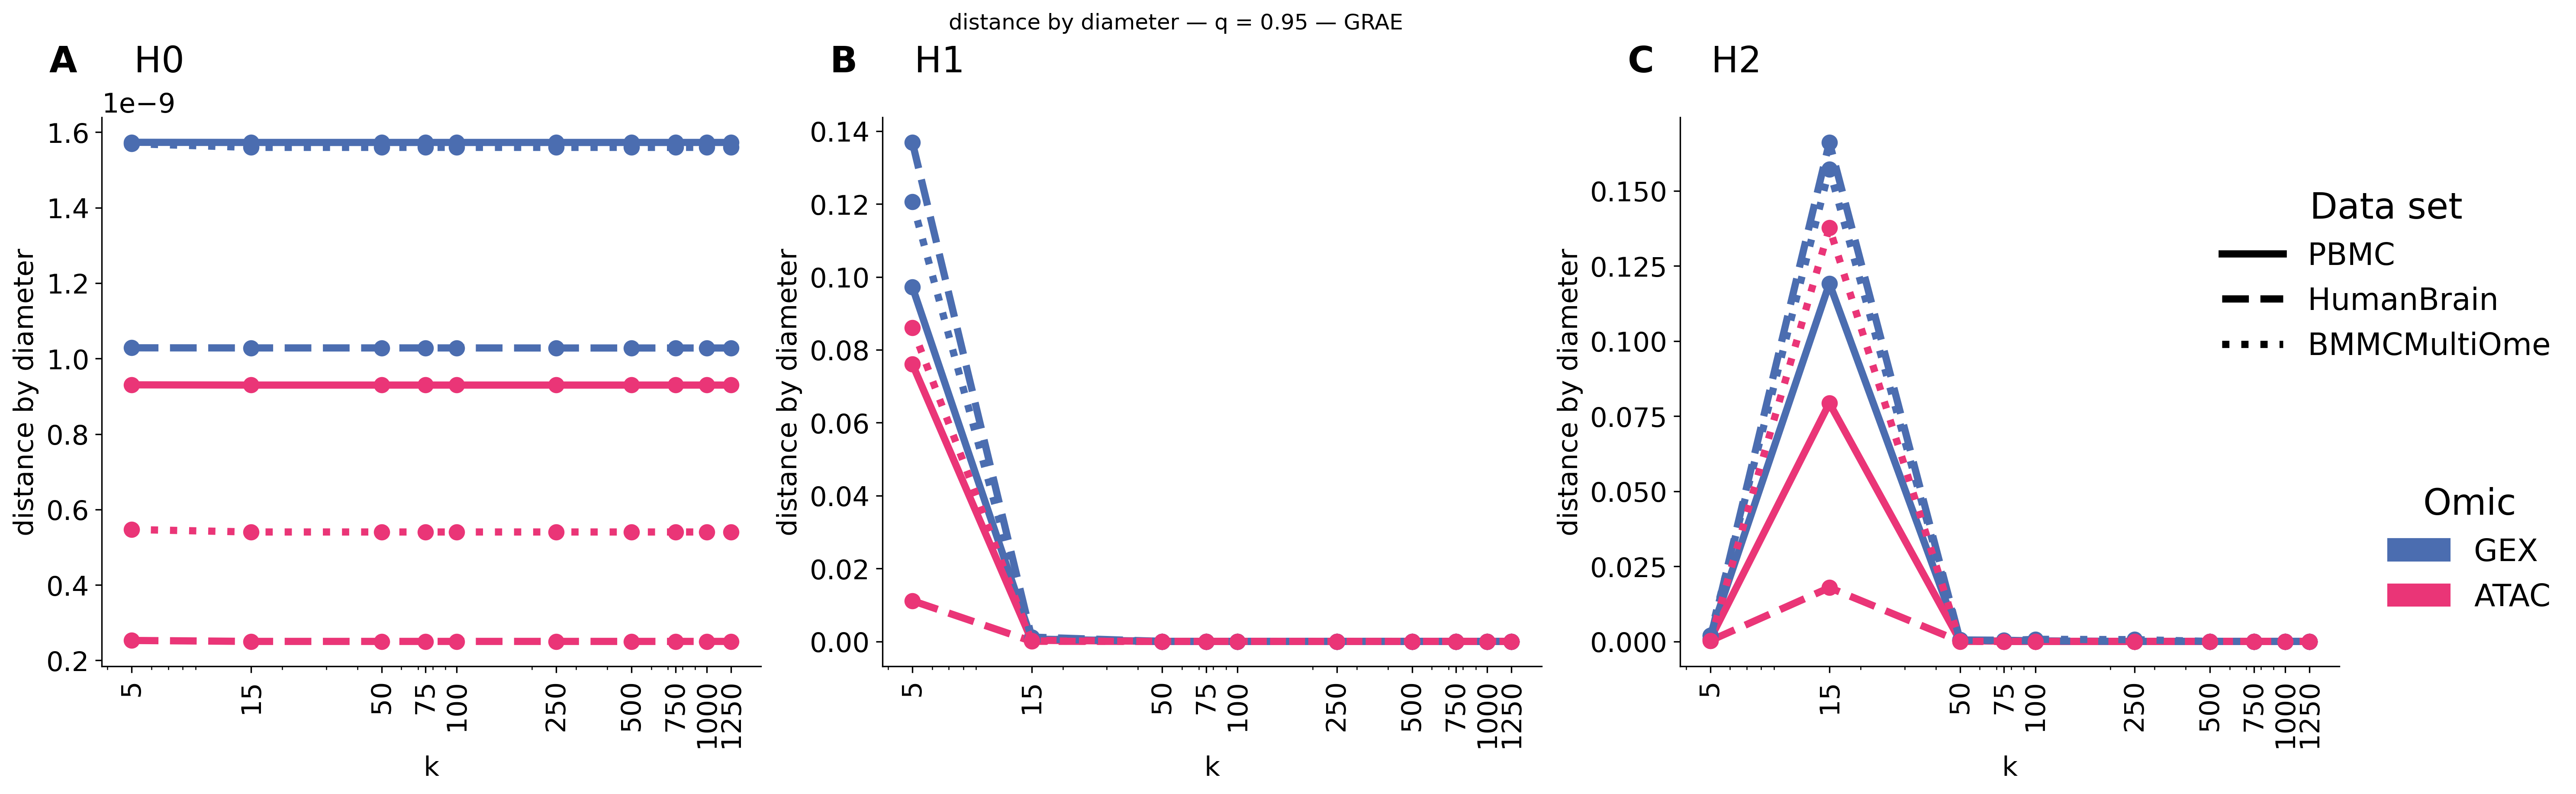

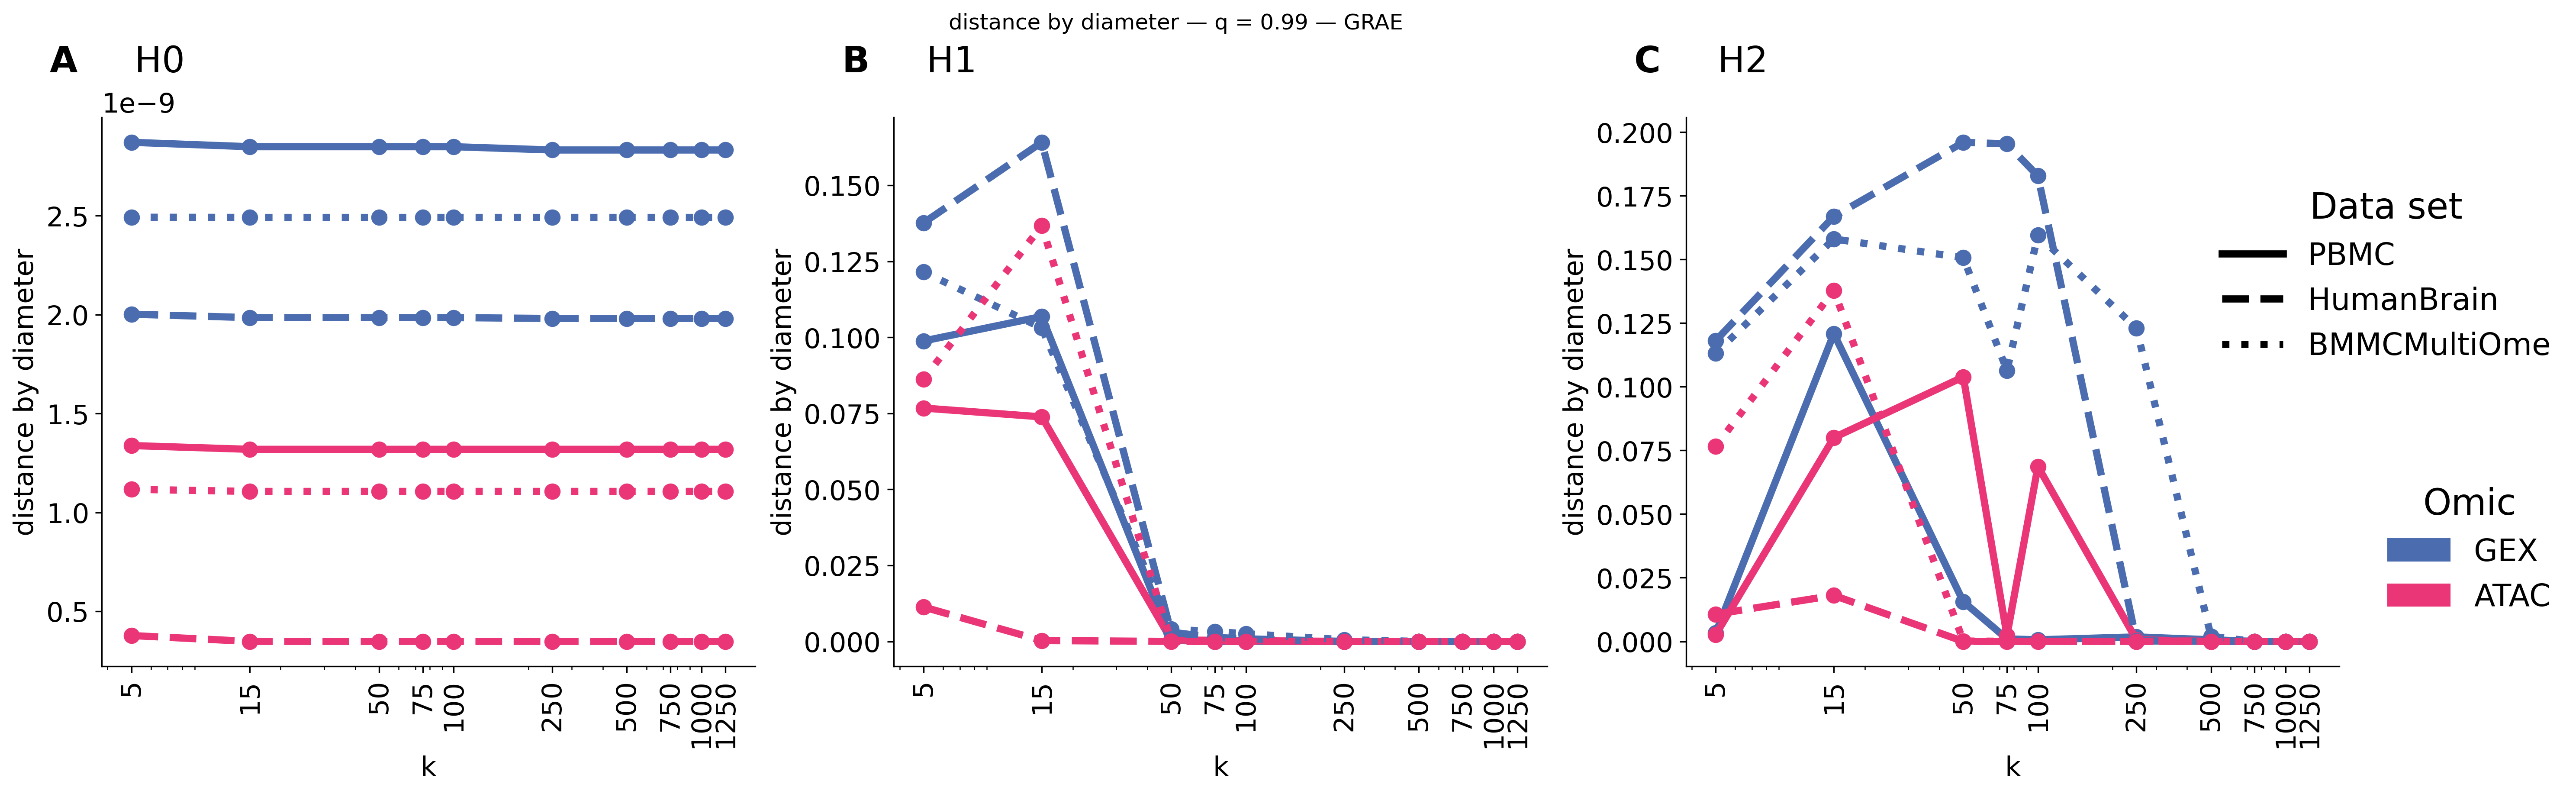

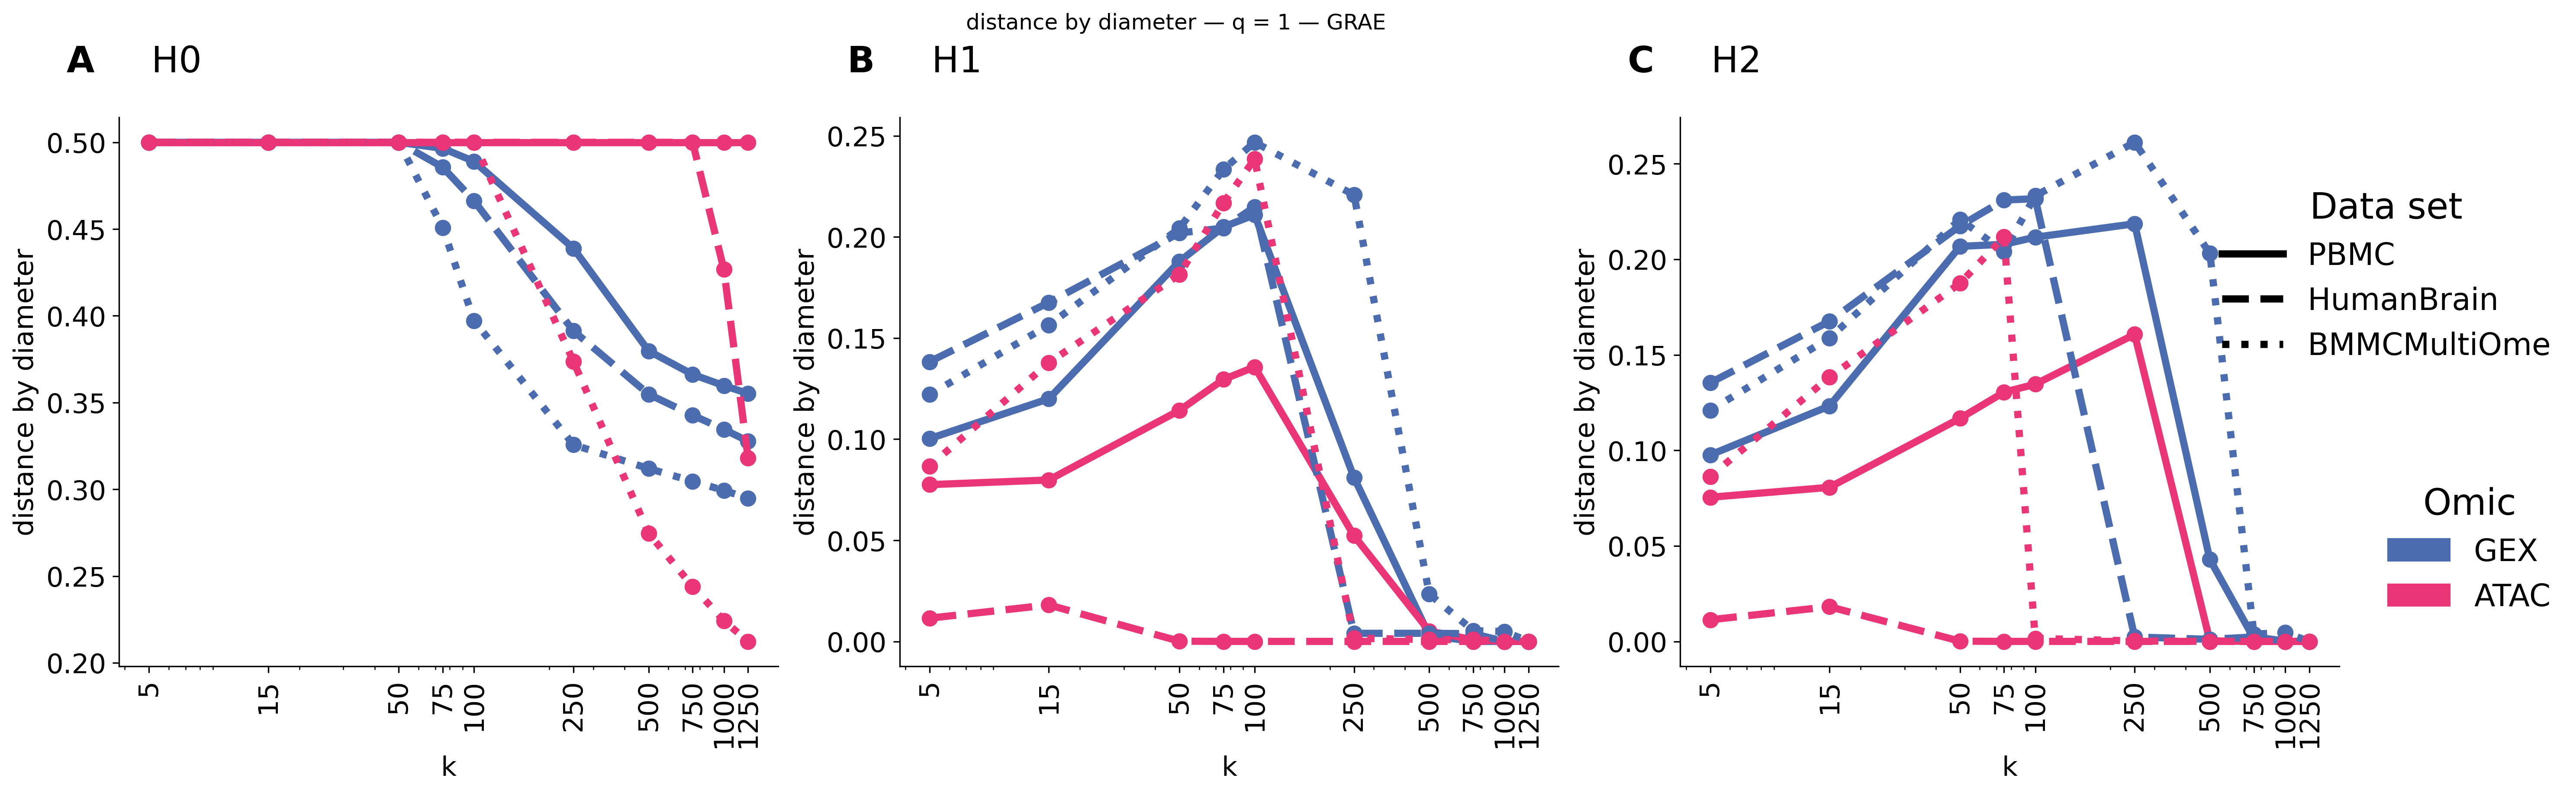

In [3]:
datasets = ["PBMC", "HumanBrain","BMMCMultiOme"]
omics = ["GEX", "Peak"]
dims = [0, 1, 2]
distances = ["distance_by_diameter"]

omic_colors = {"GEX": colors_to_use[19], "Peak": colors_to_use[16]}
omic_labels = {"GEX": "GEX", "Peak": "ATAC"}
dataset_styles = {"PBMC": "-", "HumanBrain": "--", "BMMCMultiOme" : ":"}

plt.rcParams.update({
    "axes.labelsize": 15, "axes.titlesize": 15,
    "xtick.labelsize": 15, "ytick.labelsize": 15,
    "lines.linewidth": 4, "figure.dpi": 300})

Path("Figures").mkdir(exist_ok=True)


def reference_curve(sub, dim, distance):
    """Return full-vs-k for H0 and largest-k-vs-k for H1/H2."""
    if sub.empty:
        return sub

    labels = pd.unique(sub[["label_a", "label_b"]].to_numpy().ravel())
    k_labels = [x for x in labels if str(x).startswith("k=")]
    reference = "full" if dim == 0 else max(k_labels, key=k_value, default=None)

    if reference is None:
        return pd.DataFrame()

    a, b = sub["label_a"], sub["label_b"]
    a_is_k, b_is_k = a.astype(str).str.startswith("k="), b.astype(str).str.startswith("k=")

    out = sub[
        ((a == reference) & b_is_k)
        | ((b == reference) & a_is_k)
    ].copy()

    out["k"] = np.where(
        out["label_a"] == reference,
        out["label_b"].map(k_value),
        out["label_a"].map(k_value),
    )

    # Add the zero-distance reference point if it is absent.
    if dim > 0:
        ref_k = k_value(reference)
        if not np.isclose(out["k"], ref_k).any():
            row = sub.iloc[0].copy()
            row[["label_a", "label_b", distance]] = [reference, reference, 0.0]
            row["k"] = ref_k
            out = pd.concat([out, row.to_frame().T], ignore_index=True)

    return out.sort_values("k").drop_duplicates("k")


plot_df = df[
    df["dataset"].isin(datasets)
    & df["omic"].isin(omics)
    & df["homology_dim"].isin(dims)
].copy()

quantiles = sorted(plot_df["quantile"].dropna().unique())
ks = sorted({
    int(k_value(x))
    for x in pd.unique(plot_df[["label_a", "label_b"]].to_numpy().ravel())
    if str(x).startswith("k=") and np.isfinite(k_value(x))
})

for q in quantiles:
    q_df = plot_df[np.isclose(plot_df["quantile"], q)]

    for distance in distances:
        fig, axs = plt.subplots(
            1, 3, figsize=(18, 6),
            constrained_layout=True,
        )

        for i, (ax, dim) in enumerate(zip(axs, dims)):
            for dataset in datasets:
                for omic in omics:
                    sub = q_df[
                        (q_df["dataset"] == dataset)
                        & (q_df["omic"] == omic)
                        & (q_df["homology_dim"] == dim)
                    ]

                    line = reference_curve(sub, dim, distance)
                    if line.empty:
                        continue

                    ax.plot(
                        line["k"], line[distance],
                        color=omic_colors[omic],
                        linestyle=dataset_styles[dataset],
                        marker="o",
                        markersize=8,
                    )

            ax.set_title(
                rf"$\mathbf{{{string.ascii_uppercase[i]}}}$     H{dim}",
                loc="left", size=20, pad=10, y=1.05, x=-0.08,
            )
            ax.set(
                xscale="log",
                xlabel="k",
                ylabel=distance.replace("_", " "),
            )
            ax.set_xticks(ks)
            ax.set_xticklabels(ks, rotation=90)
            ax.spines[["top", "right"]].set_visible(False)
            ax.grid(False)

        dataset_handles = [
            Line2D(
                [0], [0], color="black",
                linestyle=dataset_styles[x],
                linewidth=4, label=x,
            )
            for x in datasets
        ]
        omic_handles = [
            mpatches.Patch(
                color=omic_colors[x],
                label=omic_labels[x],
            )
            for x in omics
        ]

        fig.legend(
            handles=dataset_handles,
            bbox_to_anchor=(1.1, 0.80),
            loc="upper right",
            title="Data set",
            fontsize=17,
            title_fontsize=20,
            frameon=False,
        )
        fig.legend(
            handles=omic_handles,
            bbox_to_anchor=(1.1, 0.42),
            loc="upper right",
            title="Omic",
            fontsize=17,
            title_fontsize=20,
            frameon=False,
        )

        q_name = f"{q:g}".replace(".", "_")
        fig.suptitle(f"{distance.replace('_', ' ')} — q = {q:g} — GRAE")

        fig.savefig(
            f"Figures/Stability_kNN_GRAE_{distance}_q{q_name}.png",
            dpi=300,
            bbox_inches="tight",
            pad_inches=0.3,
        )
        plt.show()
        plt.close(fig)

## Subsampling

In [3]:
datasets = ["PBMC", "HumanBrain","BMMCMultiOme"]
omics = ["GEX", "Peak"]
dims = [0, 1, 2]
distances = ["distance_by_diameter"]

omic_colors = {"GEX": colors_to_use[19], "Peak": colors_to_use[16]}
omic_labels = {"GEX": "GEX", "Peak": "ATAC"}
dataset_styles = {"PBMC": "-", "HumanBrain": "--", "BMMCMultiOme" : ":"}

base = Path("Datasets")


def subset_value(x):
    """Convert labels like 'subset_3' to integer 3."""
    m = re.search(r"subset_(\d+)", str(x))
    return int(m.group(1)) if m else np.nan


def read_all():
    rows = []

    for dataset in datasets:
        for omic in omics:
            outdir = (base / dataset / "XplainTDA" / omic / "Stability" / "GRAE" / "Subsampling")
            p = outdir / "pairwise_quantile_bottleneck.csv"

            if not p.exists():
                print("Missing:", p)
                continue

            tmp = pd.read_csv(p)

            tmp["dataset"] = dataset
            tmp["omic"] = omic
            tmp["source_file"] = str(p)

            tmp["subset_a_id"] = tmp["subset_a"].map(subset_value)
            tmp["subset_b_id"] = tmp["subset_b"].map(subset_value)

            rows.append(tmp)

    return pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()


df = read_all()

df0 = df[df["homology_dim"] == 0].copy()
df1 = df[df["homology_dim"] == 1].copy()
df2 = df[df["homology_dim"] == 2].copy()

df.head()

,subset_a,subset_b,homology_dim,quantile,distance,distance_by_diameter,dataset,omic,source_file,subset_a_id,subset_b_id
0,subset_0,subset_1,0,0.50,0.000019,0.000016,PBMC,GEX,Datasets/PBMC/XplainTDA/GEX/Stability/GRAE/Sub...,0,1
1,subset_0,subset_1,0,0.75,0.000069,0.000058,PBMC,GEX,Datasets/PBMC/XplainTDA/GEX/Stability/GRAE/Sub...,0,1
2,subset_0,subset_1,0,0.90,0.000270,0.000229,PBMC,GEX,Datasets/PBMC/XplainTDA/GEX/Stability/GRAE/Sub...,0,1
3,subset_0,subset_1,0,0.95,0.000713,0.000605,PBMC,GEX,Datasets/PBMC/XplainTDA/GEX/Stability/GRAE/Sub...,0,1
4,subset_0,subset_1,0,0.99,0.002679,0.002273,PBMC,GEX,Datasets/PBMC/XplainTDA/GEX/Stability/GRAE/Sub...,0,1


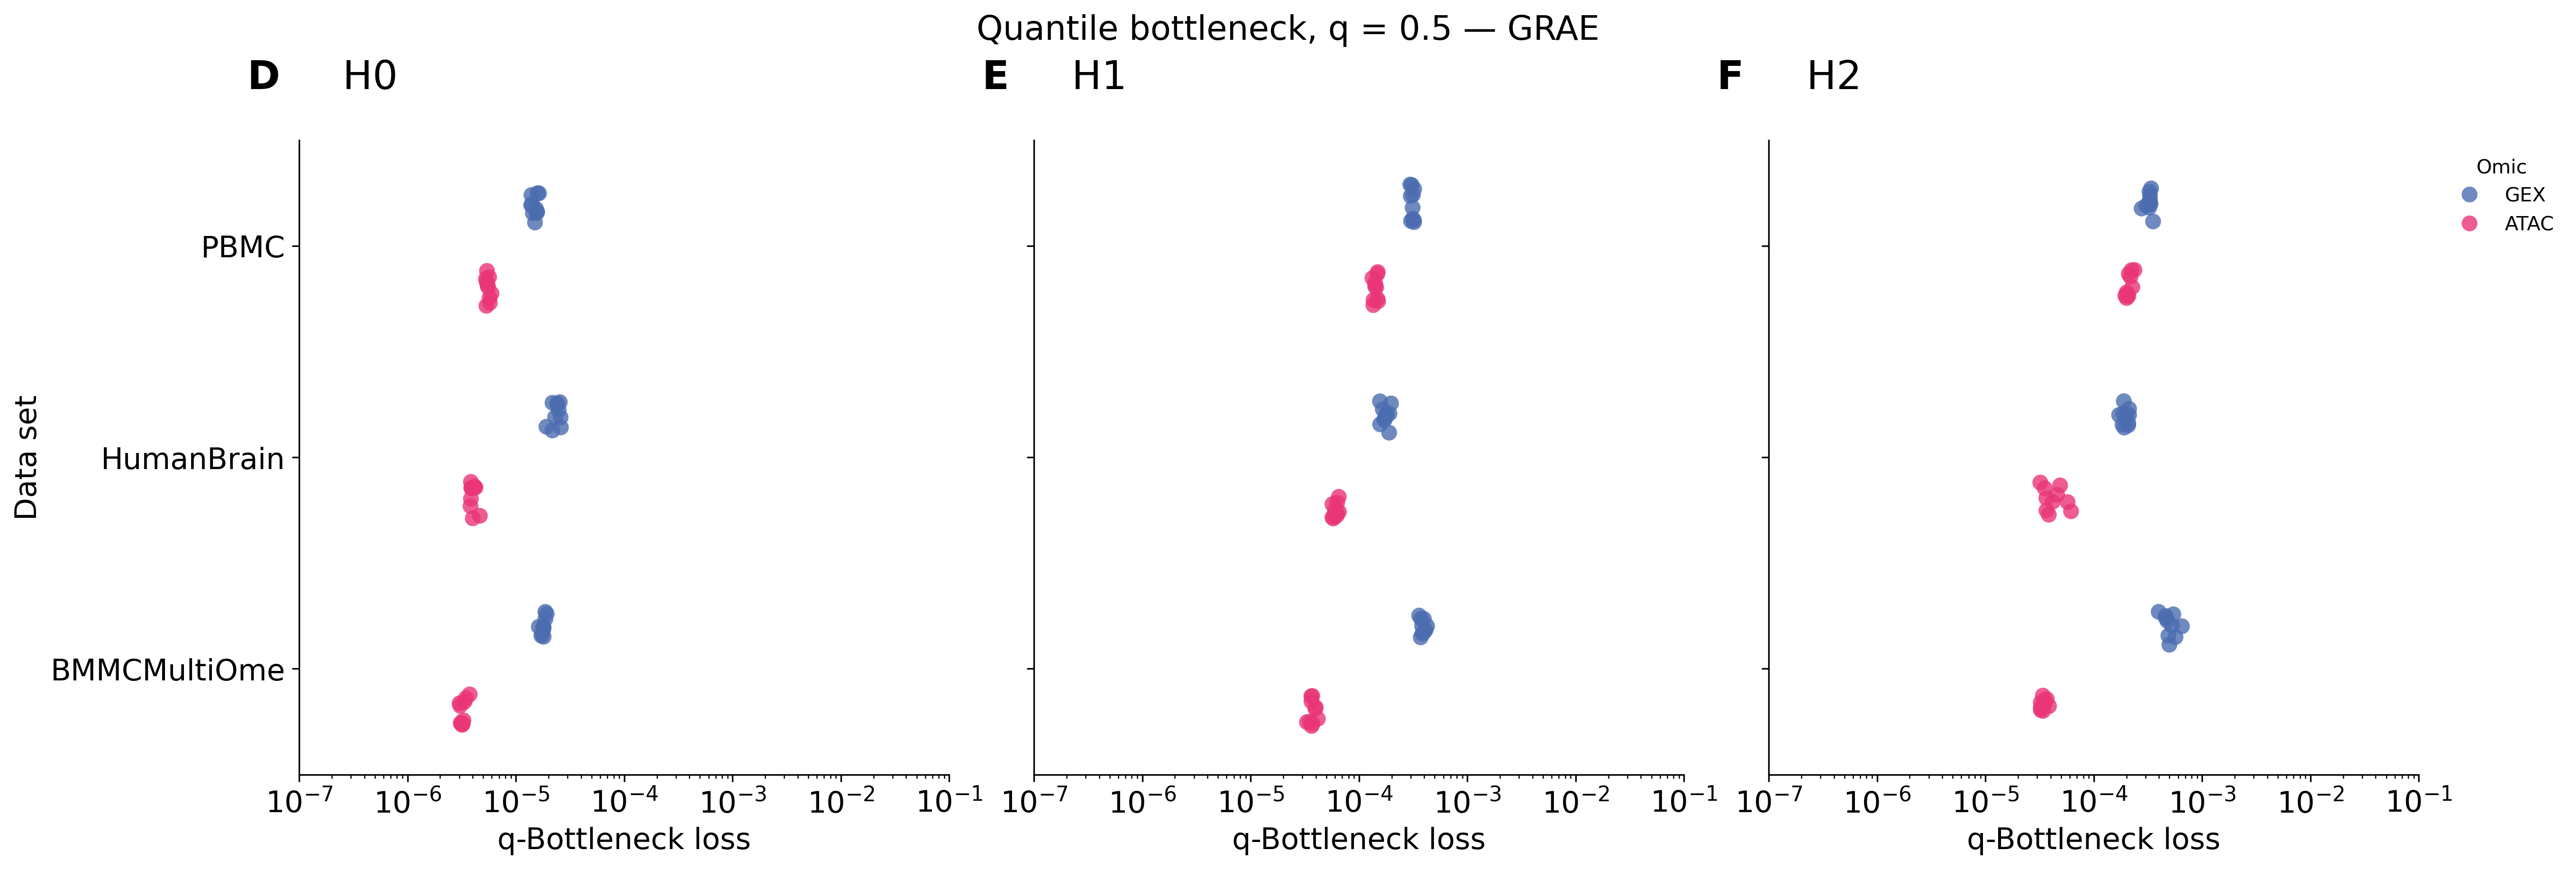

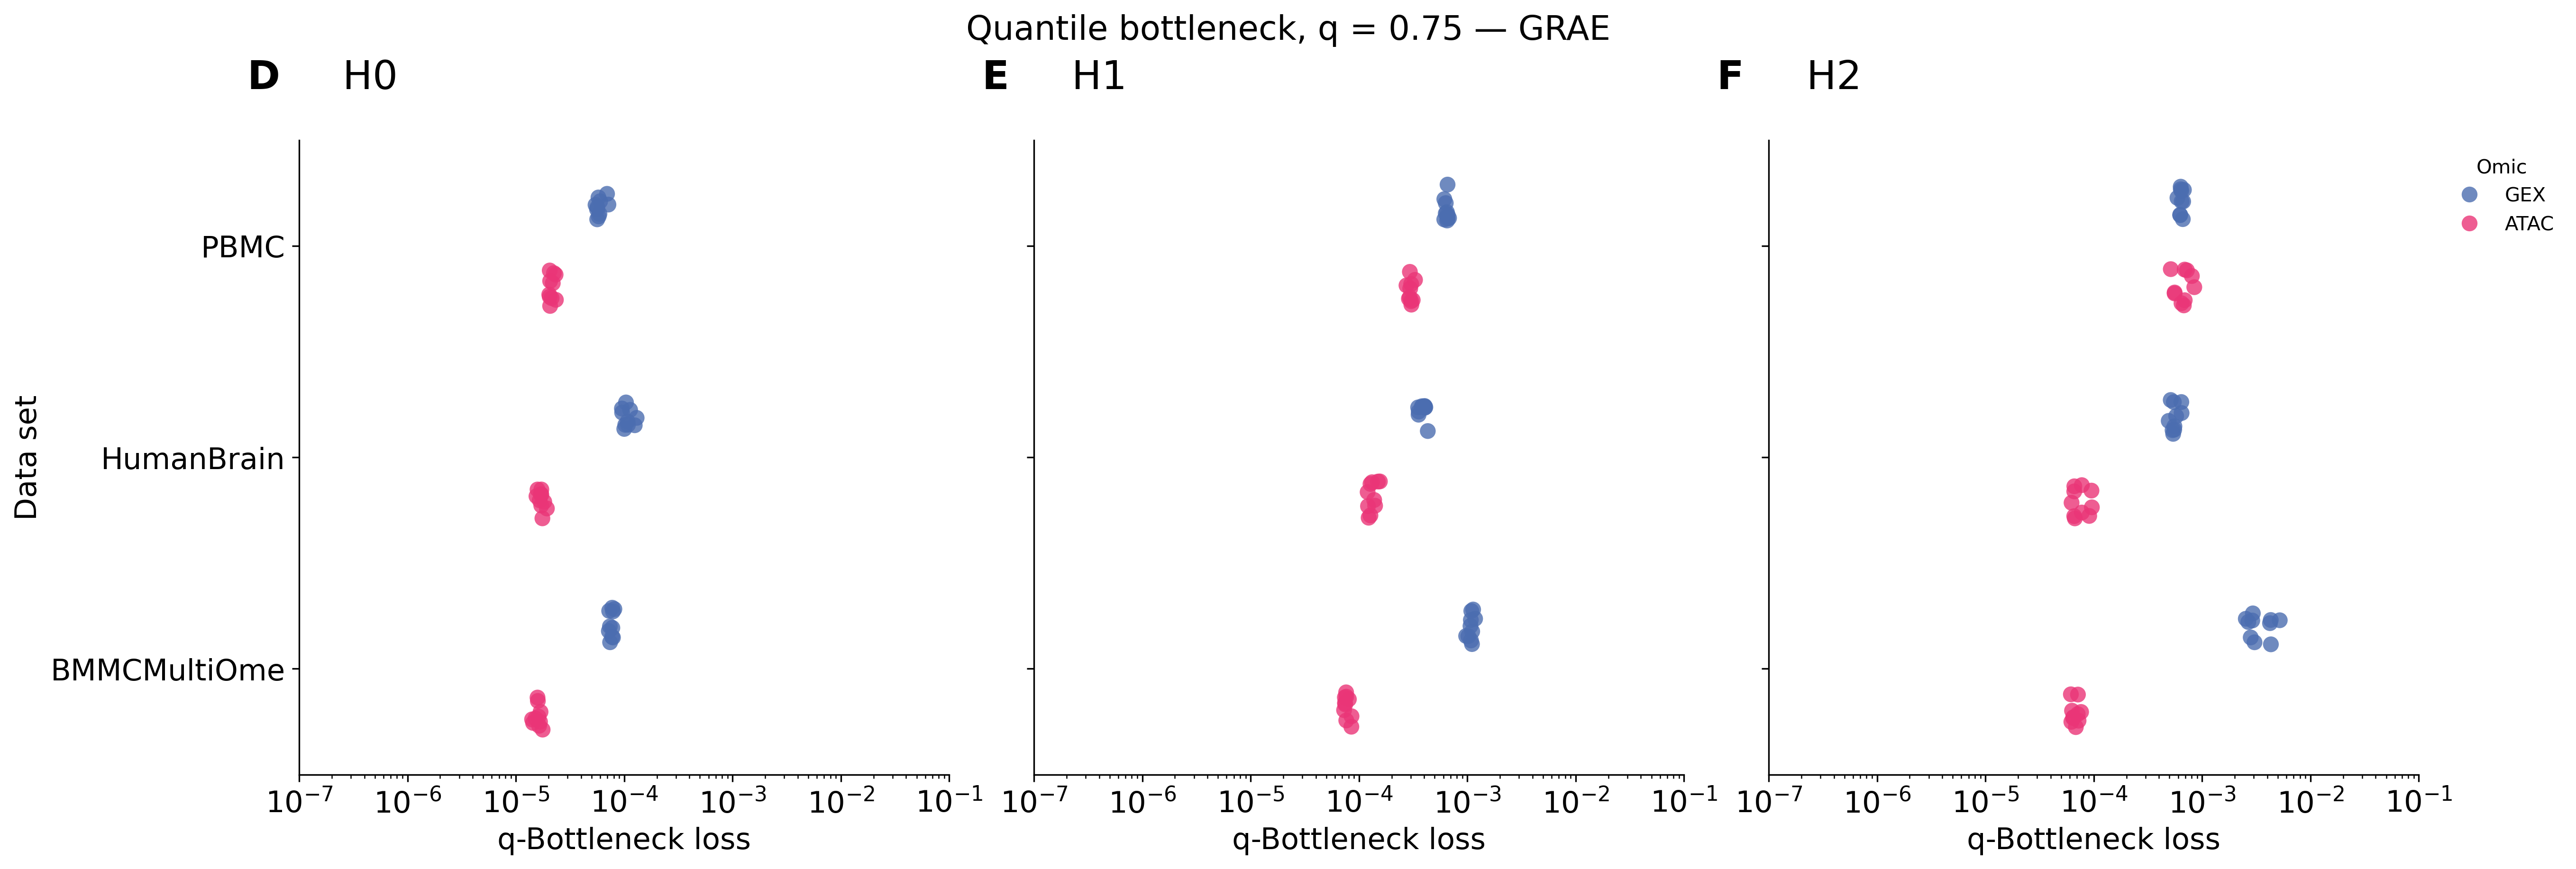

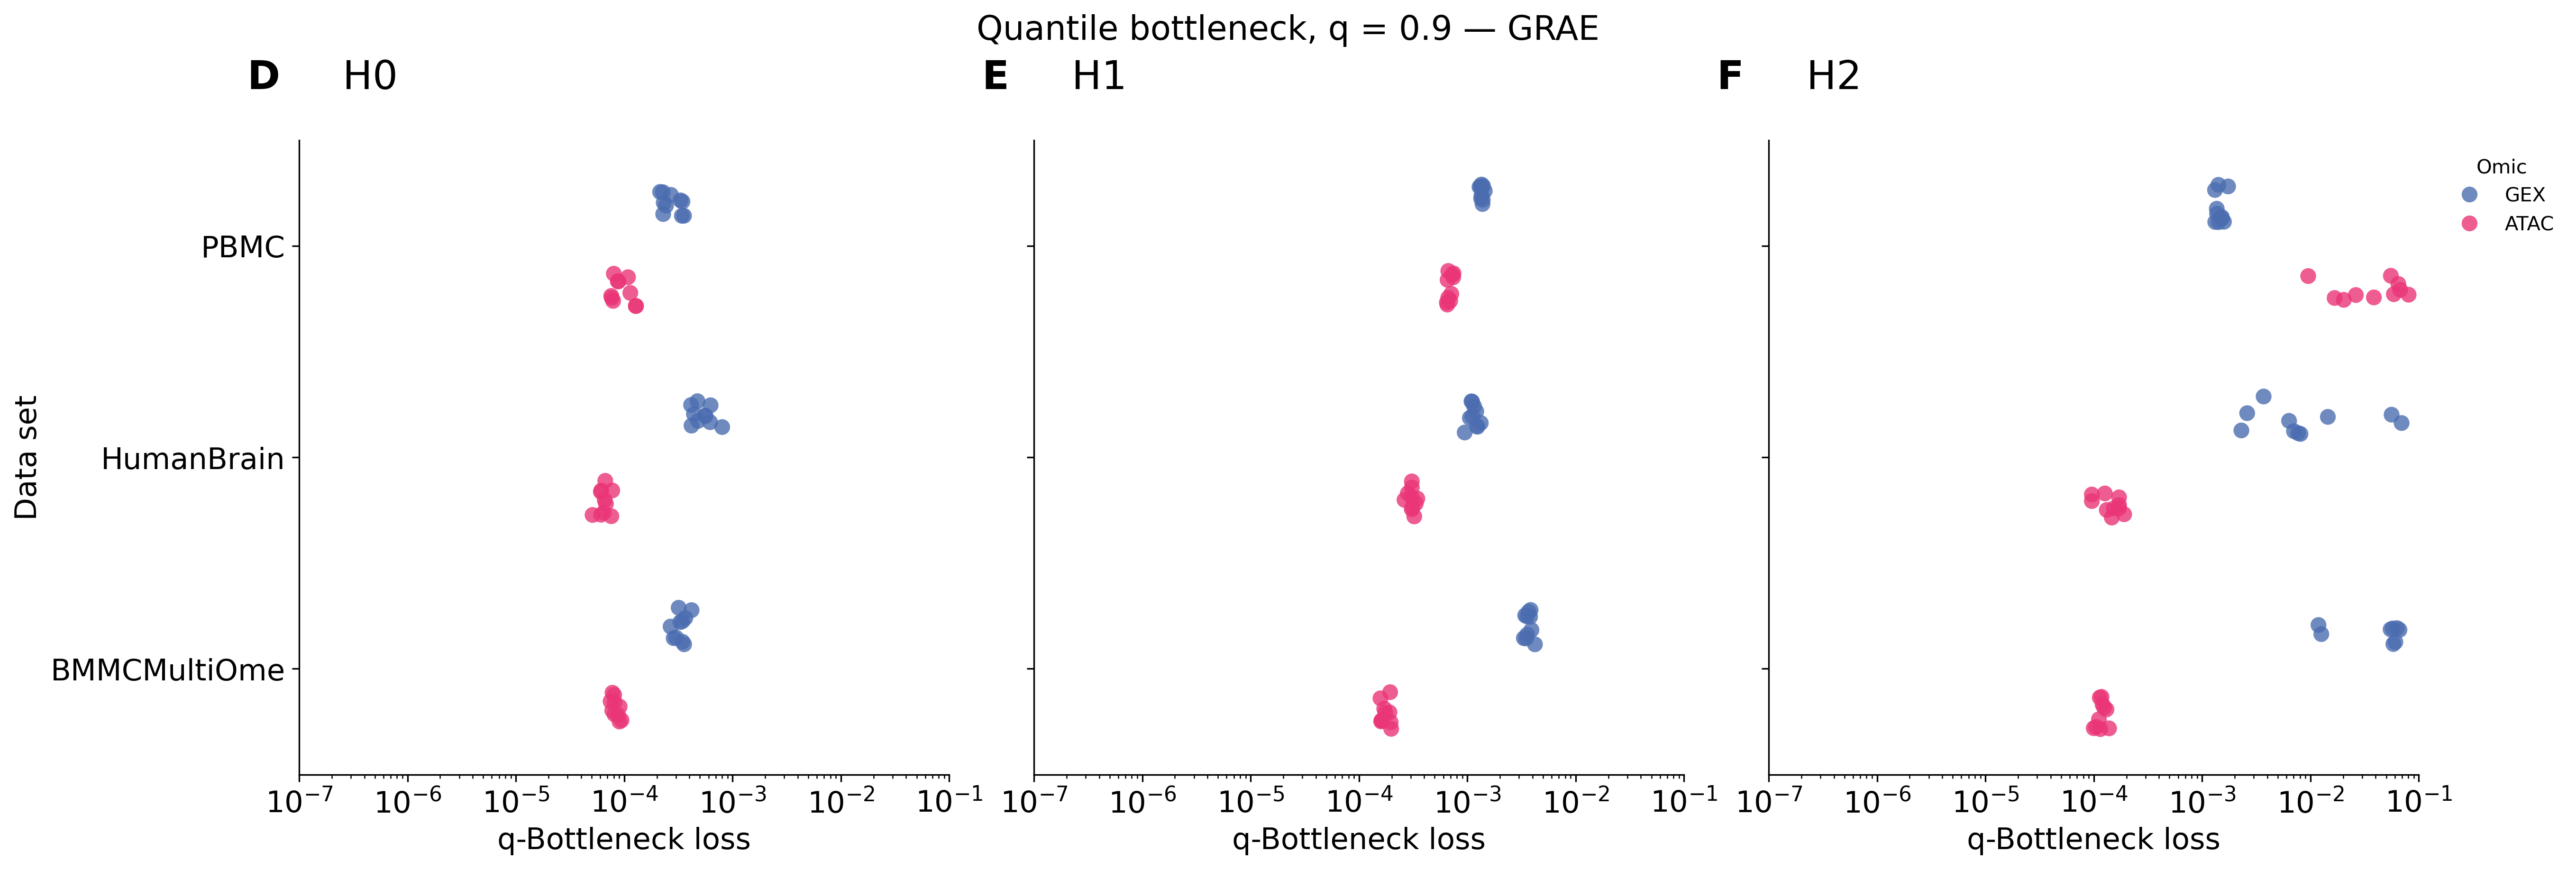

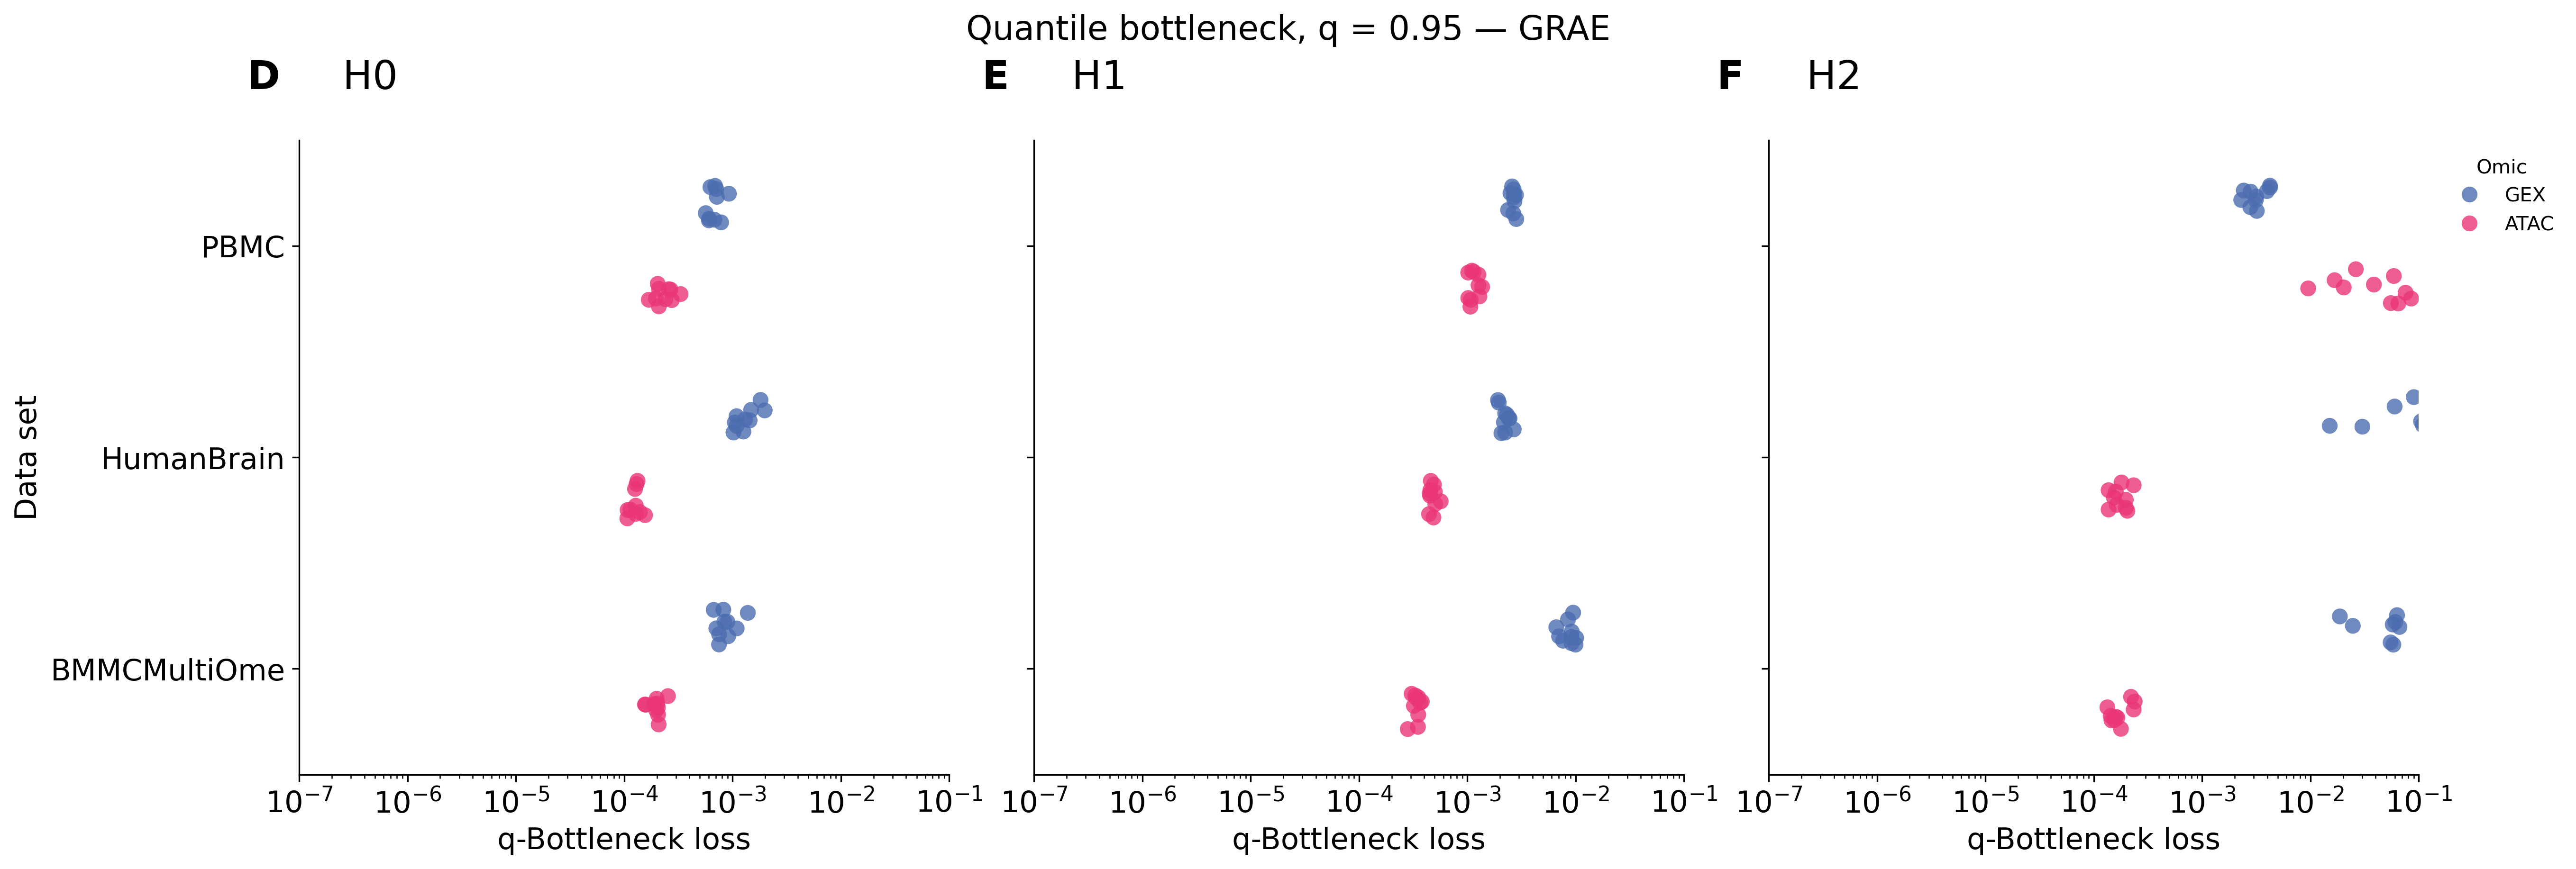

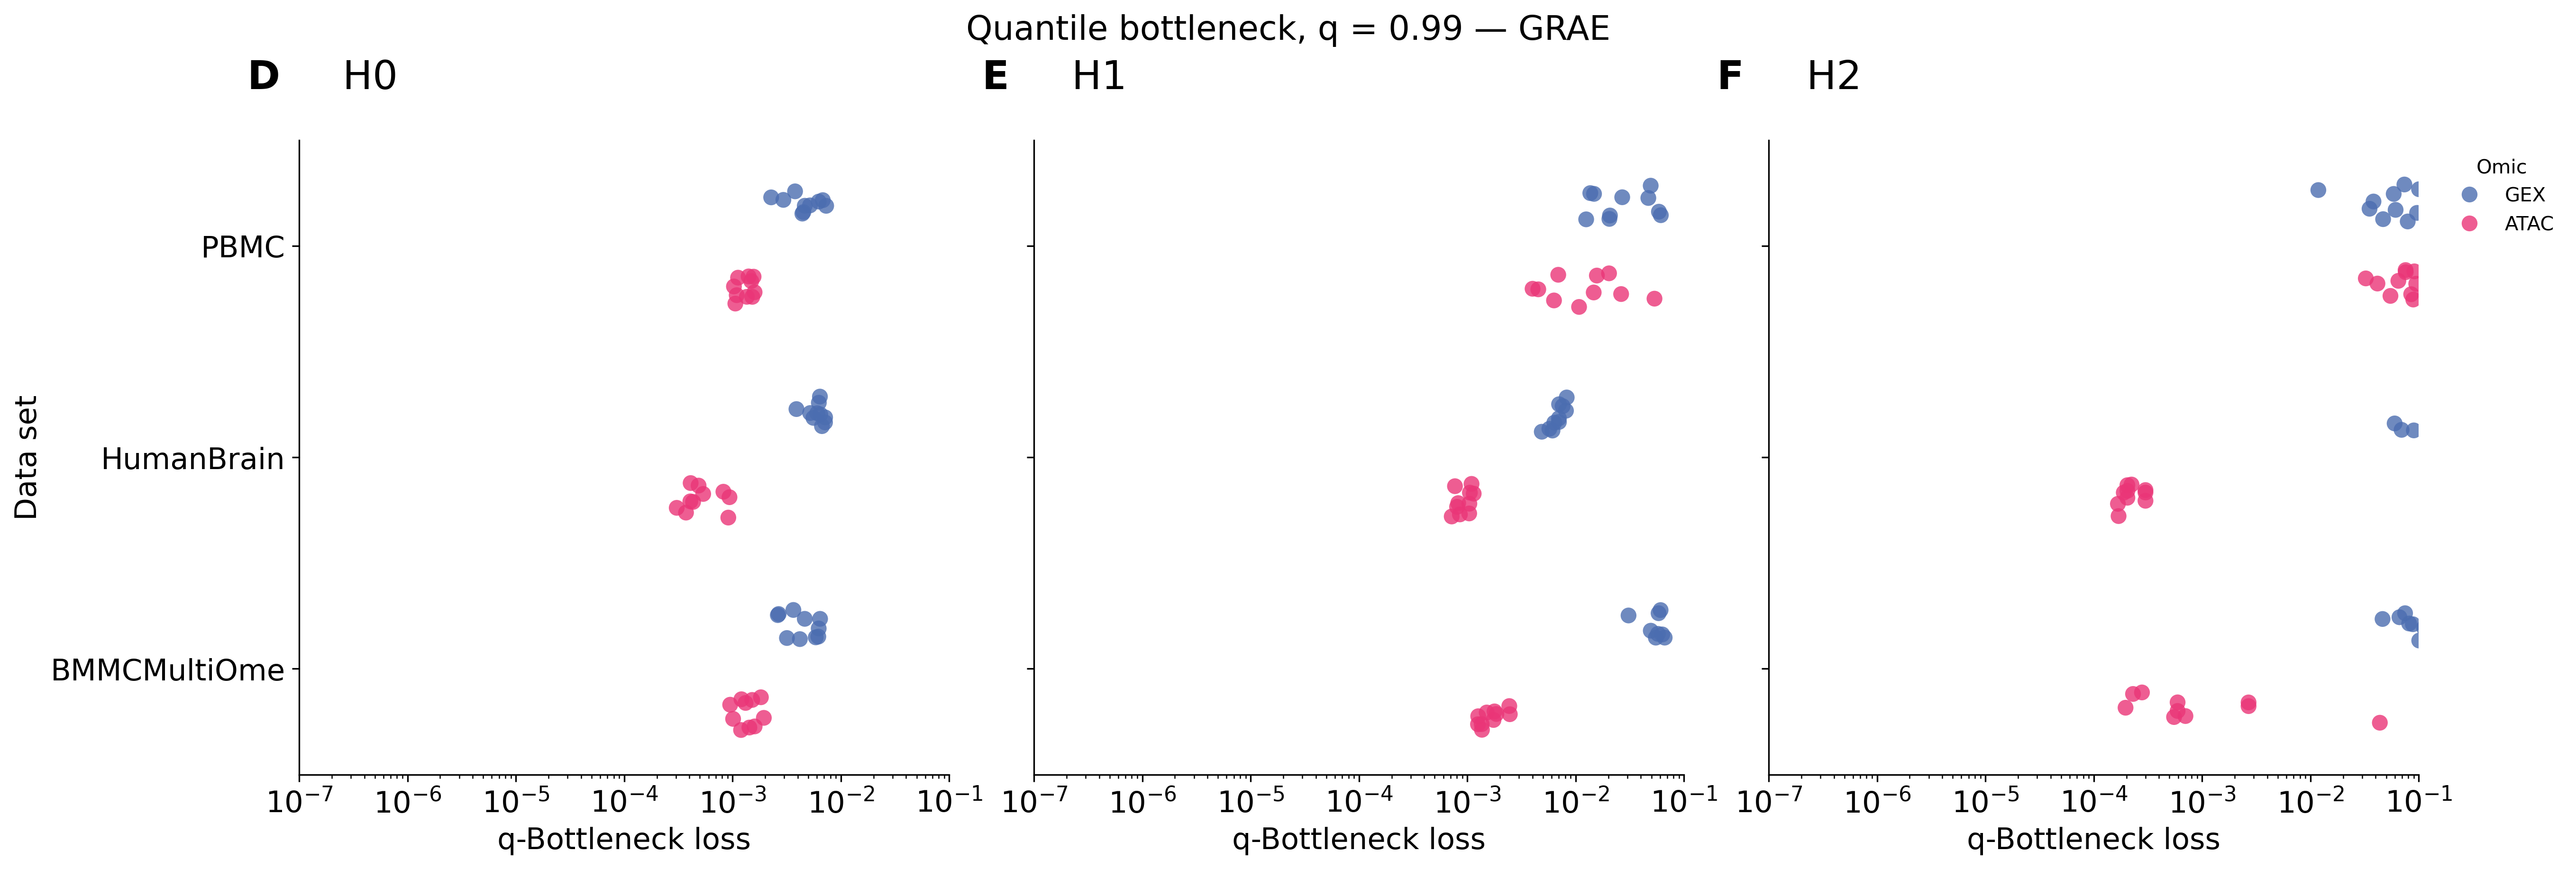

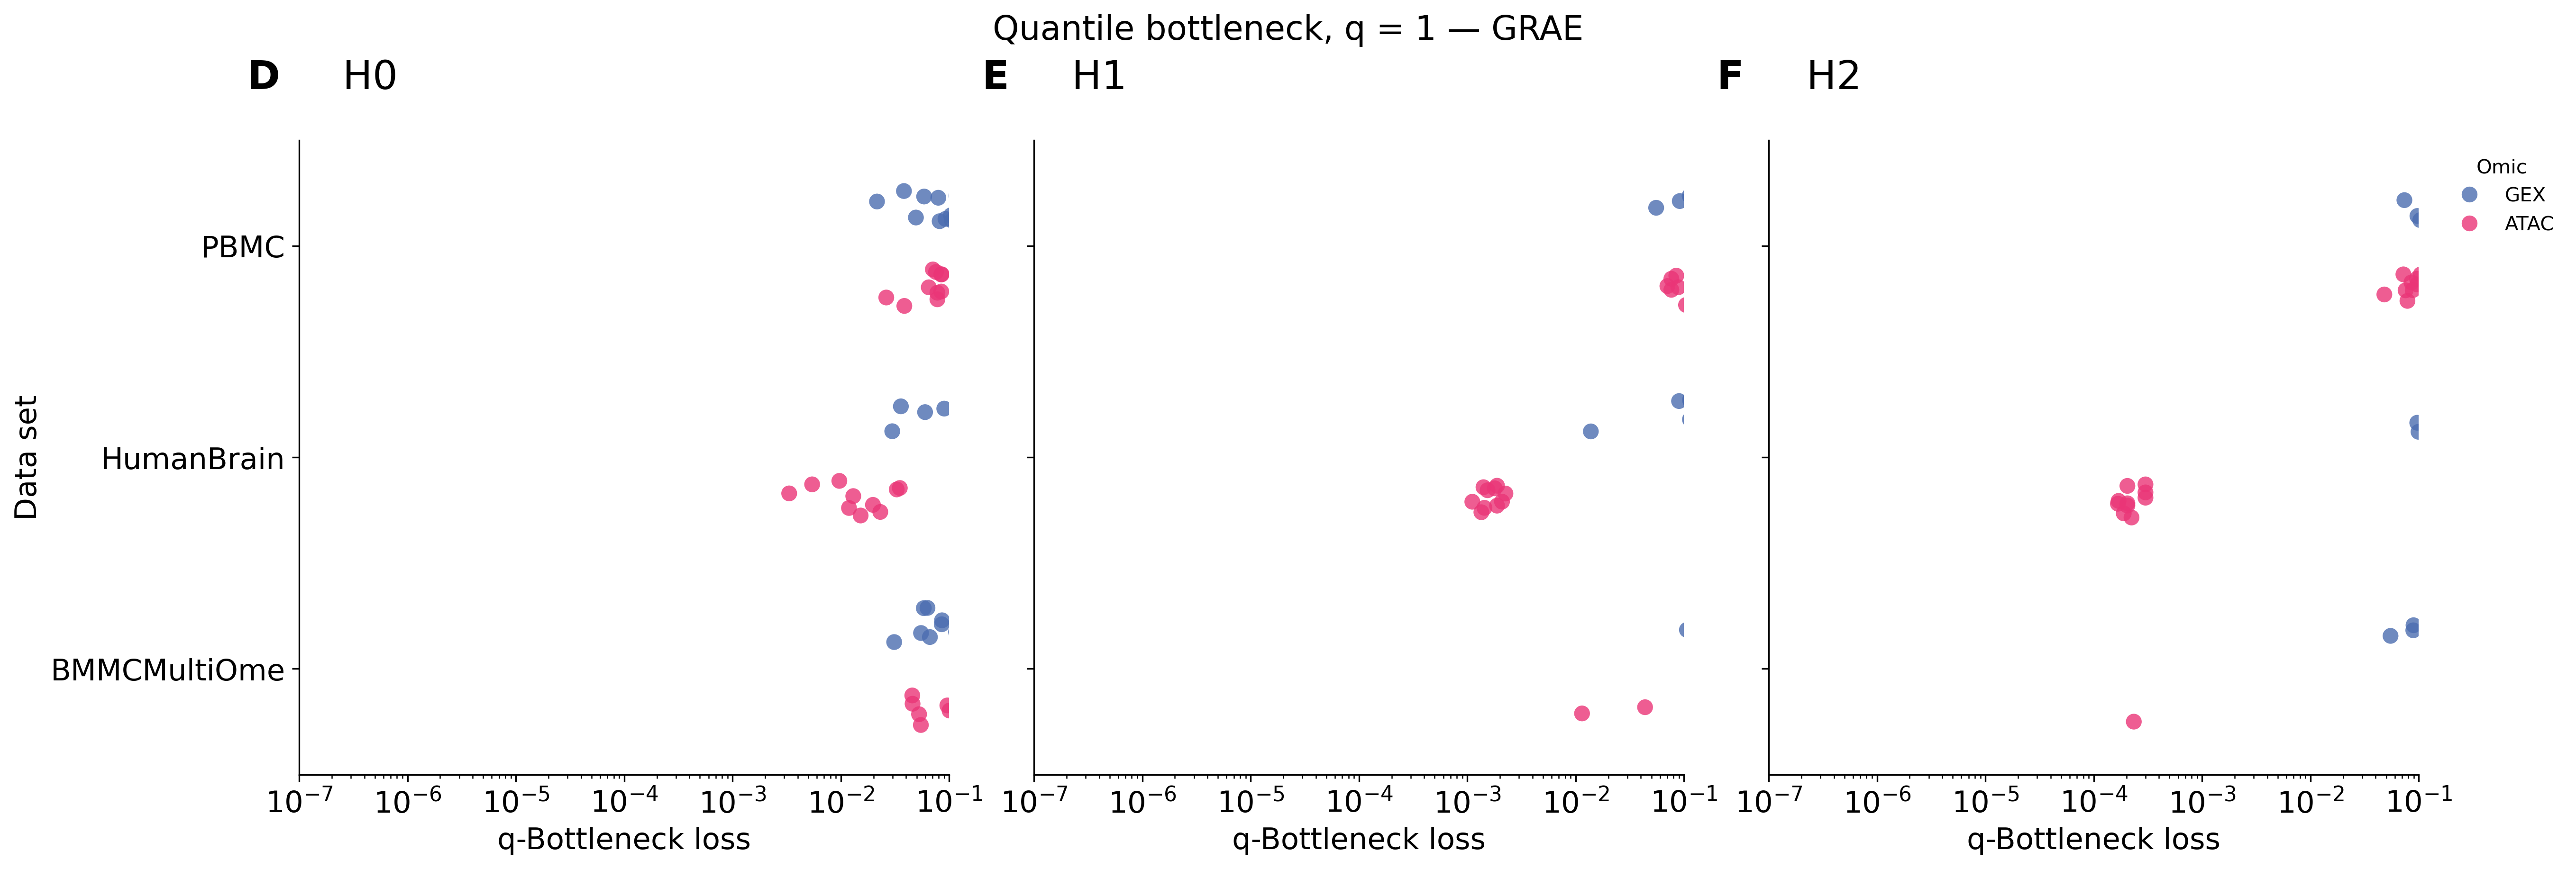

In [4]:
plt.rcParams.update({
"axes.labelsize": 15, "axes.titlesize": 15,
"xtick.labelsize": 15, "ytick.labelsize": 15,
"figure.dpi": 300,
})

plot_df = df[
df["dataset"].isin(datasets)
& df["omic"].isin(omics)
& df["homology_dim"].isin(dims)
].copy()

plot_df["omic_label"] = plot_df["omic"].map(omic_labels)

quantiles = sorted(plot_df["quantile"].unique())
distance = "distance_by_diameter"

hue_order = [omic_labels[x] for x in omics]
palette = {omic_labels[x]: omic_colors[x] for x in omics}

Path("Figures").mkdir(exist_ok=True)

for q in quantiles:
    fig, axs = plt.subplots(
        1, 3, figsize=(18, 6),
        constrained_layout=True,
        sharey=True)

    for i, (ax, dim) in enumerate(zip(axs, dims)):
        sub = plot_df[
            (plot_df["homology_dim"] == dim)
            & np.isclose(plot_df["quantile"], q)
            & (plot_df[distance] > 0)  # required for logarithmic scale
        ]

        sns.stripplot(
            data=sub,
            y="dataset",
            x=distance,
            hue="omic_label",
            order=datasets,
            hue_order=hue_order,
            palette=palette,
            dodge=True,
            jitter=0.18,
            size=8,
            alpha=0.8,
            ax=ax,
        )

        ax.set_title(
            rf"$\mathbf{{{string.ascii_uppercase[i + 3]}}}$     H{dim}",
            loc="left",
            size=20,
            pad=10,
            y=1.05,
            x=-0.08,
        )

        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(False)
        ax.set_xscale("log")
        ax.set_xlim(1e-7, 1e-1)
        ax.set_xticks(10.0 ** np.arange(-7, 0))
        ax.set_xlabel("q-Bottleneck loss")
        ax.set_ylabel("Data set")
        ax.set_yticks(range(0,3), datasets)

        legend = ax.get_legend()
        if legend:
            if i < len(dims) - 1:
                legend.remove()
            else:
                legend.set_title("Omic")
                legend.set_frame_on(False)
                legend.set_bbox_to_anchor((1.02, 1))
                legend._loc = 2

    q_name = f"{q:g}".replace(".", "_")
    fig.suptitle(f"Quantile bottleneck, q = {q:g} — GRAE", fontsize=17)

    fig.savefig(
        f"Figures/Stability_Subsampling_GRAE_{distance}_q{q_name}.png",
        dpi=300,
        bbox_inches="tight",
        pad_inches=0.3,
    )
    plt.show()
    plt.close(fig)

## Figure 2

In [36]:
datasets = ["PBMC", "HumanBrain","BMMCMultiOme"]
omics = ["GEX", "Peak"]
dims = [0, 1, 2]
distances = ["distance_by_diameter"]

omic_colors = {"GEX": colors_to_use[19], "Peak": colors_to_use[16]}
omic_labels = {"GEX": "GEX", "Peak": "ATAC"}
dataset_styles = {"PBMC": "-", "HumanBrain": "--", "BMMCMultiOme" : ":"}

def read_results(pattern):
    """Read every existing result file and infer dataset/omic from its path."""
    out = []
    for path in Path("Datasets").glob(pattern):
        tmp = pd.read_csv(path)
        parts = path.parts
        i = parts.index("Datasets")
        tmp["dataset"], tmp["omic"] = parts[i + 1], parts[i + 3]
        out.append(tmp)
    return pd.concat(out, ignore_index=True) if out else pd.DataFrame()


def k_value(x):
    m = re.search(r"k=(\d+)", str(x))
    return np.inf if x == "full" else int(m.group(1)) if m else np.nan


def knn_curve(sub, dim):
    """H0 uses the full graph; H1/H2 use the largest k as reference."""
    if sub.empty:
        return sub

    labels = pd.unique(sub[["label_a", "label_b"]].to_numpy().ravel())
    ks = [x for x in labels if str(x).startswith("k=")]
    ref = "full" if dim == 0 else max(ks, key=k_value, default=None)
    if ref is None:
        return pd.DataFrame()

    a, b = sub["label_a"].astype(str), sub["label_b"].astype(str)
    out = sub[
        ((a == ref) & b.str.startswith("k="))
        | ((b == ref) & a.str.startswith("k="))
    ].copy()

    out["k"] = np.where(
        out["label_a"] == ref,
        out["label_b"].map(k_value),
        out["label_a"].map(k_value),
    )
    return out.sort_values("k").drop_duplicates("k")


knn = read_results(
    "*/XplainTDA/*/Stability/GRAE/kNN/quantile_bottleneck_metrics.csv"
)
sub = read_results(
    "*/XplainTDA/*/Stability/GRAE/Subsampling/pairwise_quantile_bottleneck.csv"
)

for frame in (knn, sub):
    if not frame.empty:
        frame.query(
            "dataset in @datasets and omic in @omics "
            "and homology_dim in @dims",
            inplace=True,
        )
        frame.drop(frame.index[~np.isclose(frame["quantile"], q)], inplace=True)

datasets = [
    d for d in datasets
    if (not knn.empty and d in knn["dataset"].values)
    or (not sub.empty and d in sub["dataset"].values)
]
omics = [
    o for o in omics
    if (not knn.empty and o in knn["omic"].values)
    or (not sub.empty and o in sub["omic"].values)
]

BASE = Path("Datasets")

def numeric_label(value, pattern, default=np.nan):
    """Extract an integer from a string label."""
    match = re.search(pattern, str(value))
    return int(match.group(1)) if match else default


def read_results(pattern, numeric_columns):
    """Read matching result files and add path metadata and numeric labels."""
    frames = []

    for path in sorted(BASE.glob(pattern)):
        parts = path.relative_to(BASE).parts
        df = pd.read_csv(path).assign(
            dataset=parts[0],
            omic=parts[2],
            source_file=str(path),
        )

        for output, (column, regex, default) in numeric_columns.items():
            df[output] = df[column].map(
                lambda x: numeric_label(x, regex, default)
            )

        frames.append(df)

    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()


df_k = read_results(
    "*/XplainTDA/*/Stability/GRAE/kNN/quantile_bottleneck_metrics.csv",
    {
        "k1_numeric": ("label_a", r"k=(\d+)", np.inf),
        "k2_numeric": ("label_b", r"k=(\d+)", np.inf),
    },
)

df_s = read_results(
    "*/XplainTDA/*/Stability/GRAE/Subsampling/"
    "pairwise_quantile_bottleneck.csv",
    {
        "subset_a_id": ("subset_a", r"subset_(\d+)", np.nan),
        "subset_b_id": ("subset_b", r"subset_(\d+)", np.nan),
    },
)
pd.DataFrame(df_s.groupby(["dataset","omic","homology_dim"])["distance"].mean())
df_s.head()

,subset_a,subset_b,homology_dim,quantile,distance,distance_by_diameter,dataset,omic,source_file,subset_a_id,subset_b_id
0,subset_0,subset_1,0,0.50,0.000027,0.000018,BMMCMultiOme,GEX,Datasets/BMMCMultiOme/XplainTDA/GEX/Stability/...,0,1
1,subset_0,subset_1,0,0.75,0.000117,0.000079,BMMCMultiOme,GEX,Datasets/BMMCMultiOme/XplainTDA/GEX/Stability/...,0,1
2,subset_0,subset_1,0,0.90,0.000551,0.000371,BMMCMultiOme,GEX,Datasets/BMMCMultiOme/XplainTDA/GEX/Stability/...,0,1
3,subset_0,subset_1,0,0.95,0.000961,0.000648,BMMCMultiOme,GEX,Datasets/BMMCMultiOme/XplainTDA/GEX/Stability/...,0,1
4,subset_0,subset_1,0,0.99,0.006546,0.004412,BMMCMultiOme,GEX,Datasets/BMMCMultiOme/XplainTDA/GEX/Stability/...,0,1


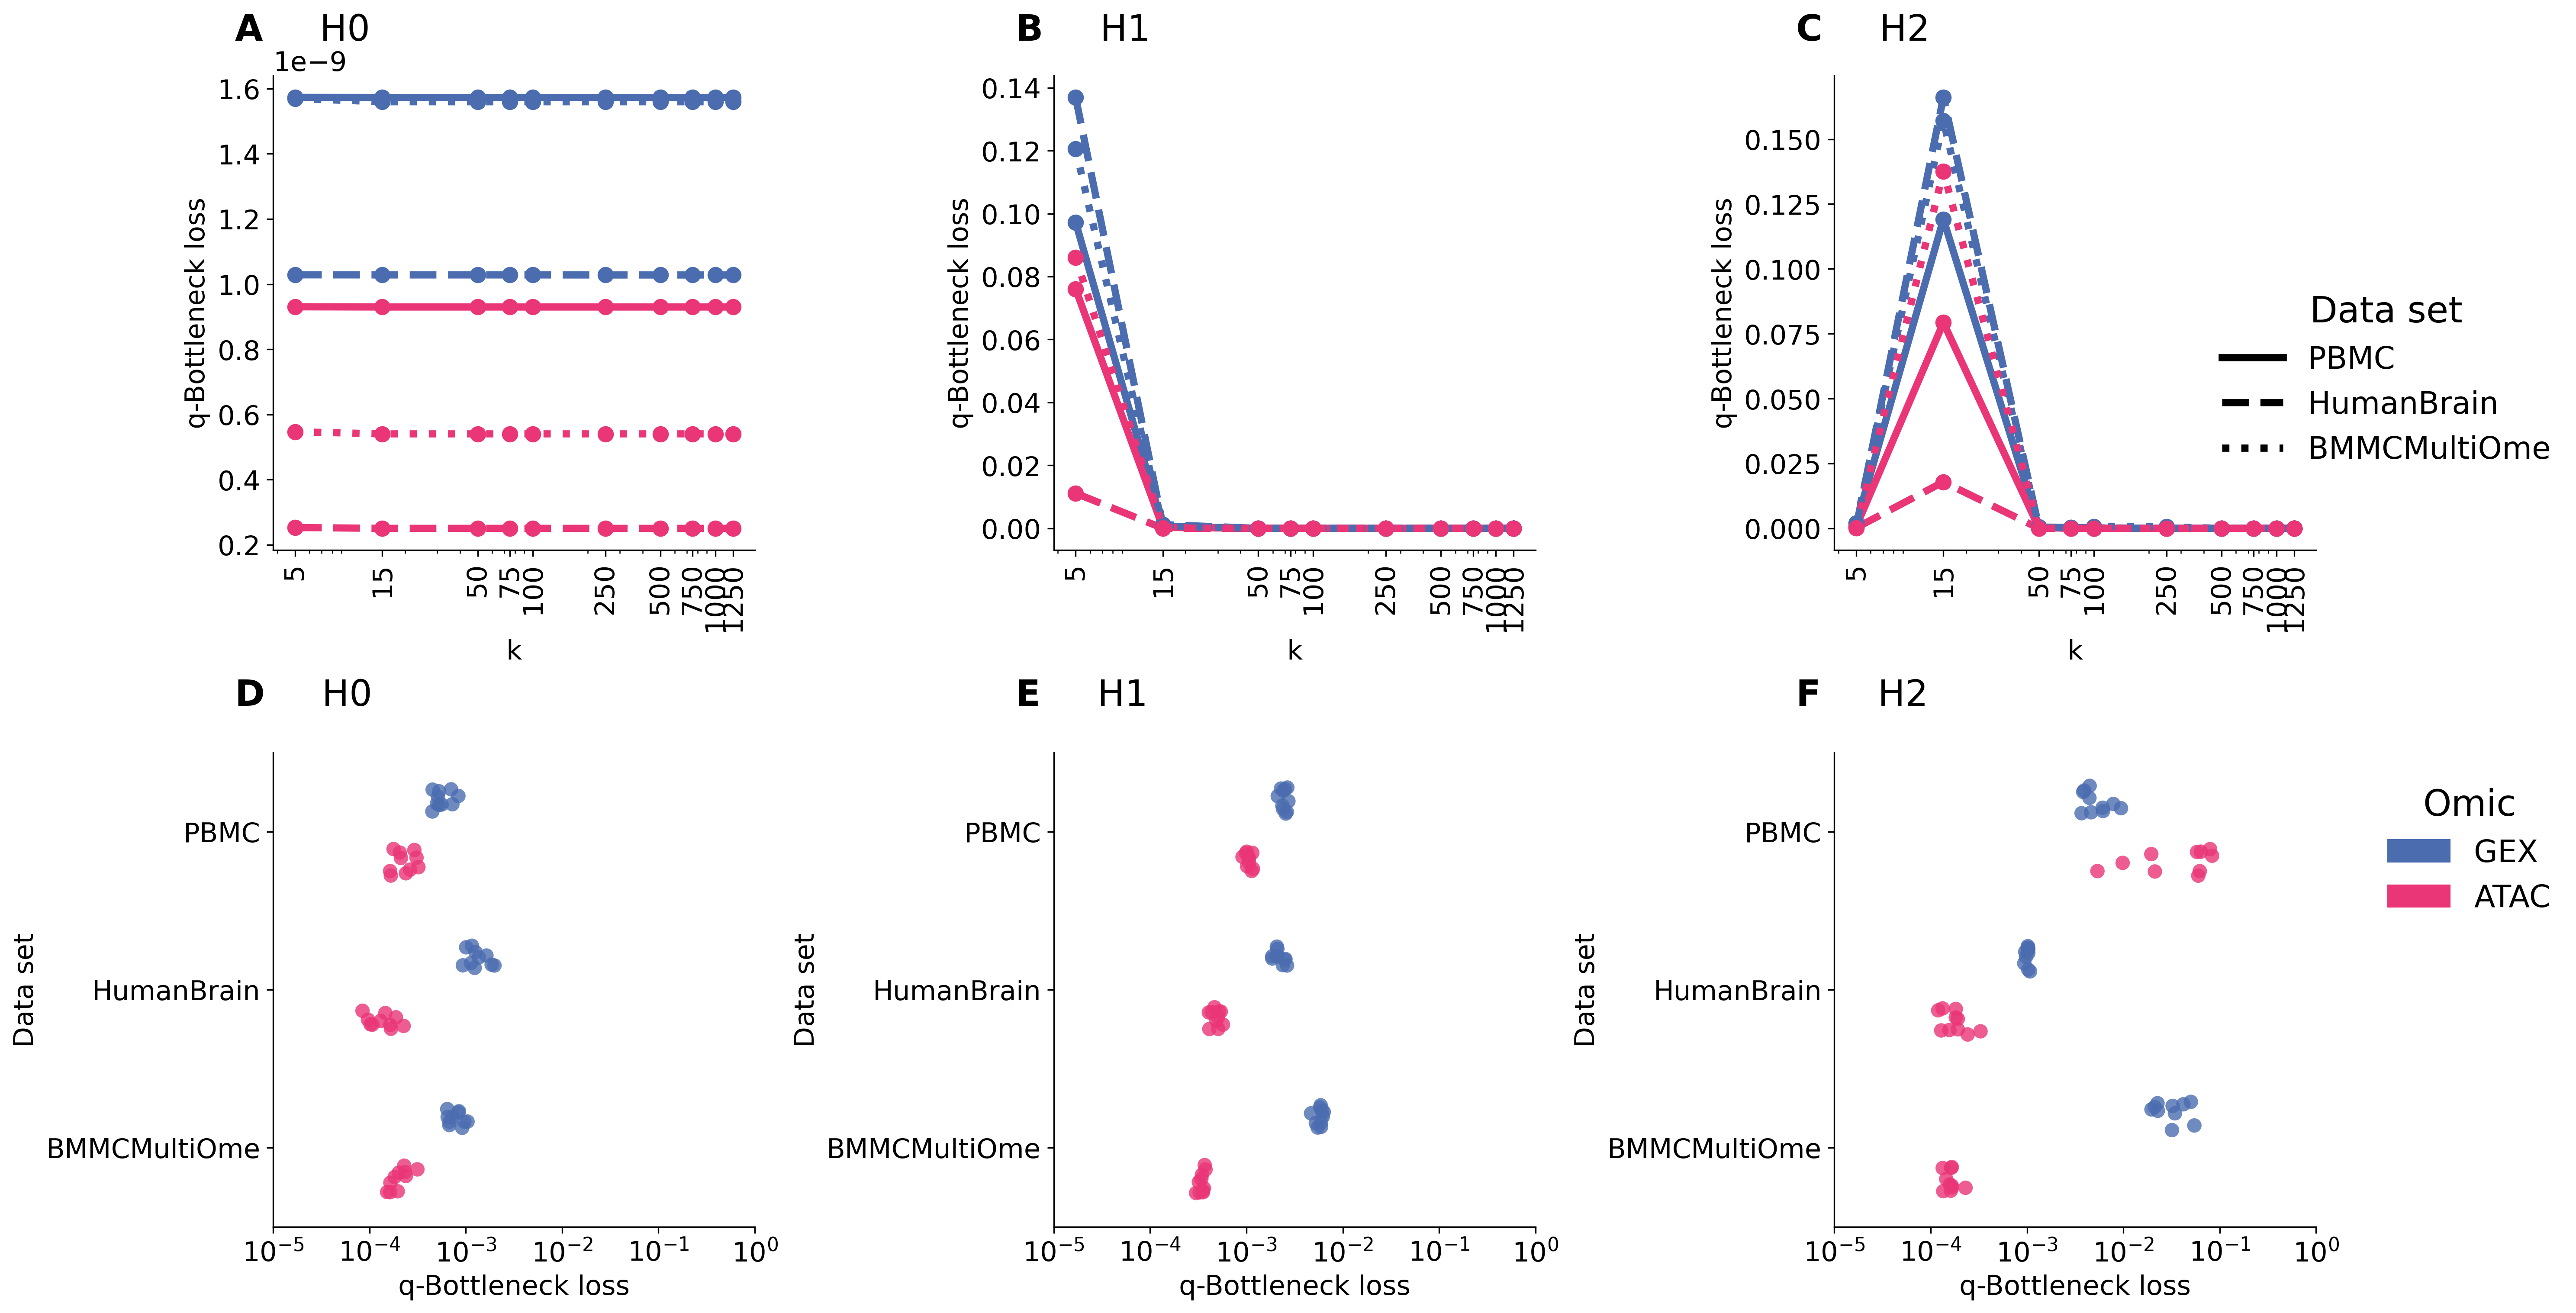

In [37]:
q=0.95
distance="distance_by_diameter"
# New outputs are in long format: select q=0.95 first.
df_k = df_k.loc[np.isclose(df_k["quantile"], q)].copy()
df_s = df_s.loc[np.isclose(df_s["quantile"], q)].copy()

plt.rcParams.update({
    "axes.labelsize": 15, "axes.titlesize": 15,
    "xtick.labelsize": 15, "ytick.labelsize": 15,
    "lines.linewidth": 4, "figure.dpi": 300,
})


def reference_distances(sub, dim):
    if sub.empty:
        return pd.DataFrame()

    labels = sorted(
        [
            x for x in set(sub["label_a"]) | set(sub["label_b"])
            if str(x).startswith("k=")
        ],
        key=k_value,
    )
    if not labels:
        return pd.DataFrame()

    ref = "full" if dim == 0 else labels[-1]
    out = sub.loc[
        ((sub["label_a"] == ref) & sub["label_b"].isin(labels))
        | ((sub["label_b"] == ref) & sub["label_a"].isin(labels))
    ].copy()

    out["k"] = np.where(
        out["label_a"] == ref,
        out["label_b"].map(k_value),
        out["label_a"].map(k_value),
    )

    if dim:
        row = sub.iloc[0][["dataset", "omic", "homology_dim", "quantile"]].to_dict()
        row.update(
            label_a=ref,
            label_b=ref,
            k=k_value(ref),
            **{distance: 0.0},
        )
        out = pd.concat([out, pd.DataFrame([row])], ignore_index=True)

    return out.sort_values("k")


def format_ax(ax, panel, dim, xlabel="", log_y=False):
    ax.set(xlabel=xlabel, ylabel=distance,
           yscale="log" if log_y else "linear")
    ax.set_title(
        rf"$\mathbf{{{string.ascii_uppercase[panel]}}}$     H{dim}",
        loc="left", x=-.08, y=1.1 if panel >= 3 else 1.075,
        fontsize=20, pad=0,
    )
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(False)


labels = set(df_k["label_a"]) | set(df_k["label_b"])
ks = sorted({
    int(k_value(x))
    for x in labels
    if str(x).startswith("k=") and np.isfinite(k_value(x))
})

df_s["omic_label"] = df_s["omic"].map(omic_labels)
palette = {omic_labels[o]: omic_colors[o] for o in omics}

fig, axes = plt.subplots(2, 3, figsize=(18, 10), constrained_layout=True)

# kNN stability
for col, dim in enumerate(dims):
    ax = axes[0, col]

    for dataset in datasets:
        for omic in omics:
            sub = df_k.loc[
                (df_k["dataset"] == dataset)
                & (df_k["omic"] == omic)
                & (df_k["homology_dim"] == dim)
            ]
            line = reference_distances(sub, dim)

            if not line.empty:
                ax.plot(
                    line["k"], line[distance],
                    color=omic_colors[omic],
                    linestyle=dataset_styles[dataset],
                    marker="o", markersize=8,
                )

    format_ax(ax, col, dim, "k")
    ax.set_xscale("log")
    ax.set_ylabel("q-Bottleneck loss")
    ax.set_xticks(ks, ks, rotation=90)

# Subsampling stability
for col, dim in enumerate(dims):
    ax = axes[1, col]
    sub = df_s.loc[df_s["homology_dim"] == dim]

    if not sub.empty:
        sns.stripplot(
            data=sub,
            y="dataset", x=distance, hue="omic_label",
            order=datasets,
            hue_order=list(omic_labels.values()),
            palette=palette,
            dodge=True, jitter=.18, size=8, alpha=.8,
            ax=ax,
        )
        if ax.get_legend():
            ax.get_legend().remove()

    format_ax(ax, col + 3, dim)
    ax.set_xscale("log")
    ax.set_xlim(1e-5, 1e0)
    ax.set_xticks(10.0 ** np.arange(-5, 1))
    ax.set_xlabel("q-Bottleneck loss")
    ax.set_ylabel("Data set")
    ax.set_yticks(range(0,3), datasets)

dataset_handles = [
    Line2D([], [], color="black",
           linestyle=dataset_styles[d], label=d)
    for d in datasets
]
omic_handles = [
    mpatches.Patch(color=omic_colors[o], label=omic_labels[o])
    for o in omics
]

for handles, title, anchor in [
    (dataset_handles, "Data set", (1.10, .80)),
    (omic_handles, "Omic", (1.10, .42)),
]:
    fig.legend(
        handles=handles, title=title,
        bbox_to_anchor=anchor, loc="upper right",
        fontsize=17, title_fontsize=20, frameon=False,
    )

fig.savefig("Figures/Figure2_GRAE.png", dpi=300, bbox_inches="tight", pad_inches=.3)
plt.show()

# Fig 4

In [ ]:
human_brain = {
    "Molec_Layer_Interneur": ["GAD1","GAD2","SLC32A1","SLC6A1","PVALB","KIT","BHLHE22","SCGN","RELN","CALB2"],
    "Purkinje_neuron": ["PCP2","CA8","CALB1","ITPR1","GRID2","HOMER3","RORA","FOXP2","SLC1A6","PPP1R17"],
    "Inhibitory_neuron": ["GAD1","GAD2","SLC32A1","SLC6A1","PVALB","SST","NPY","RELN","TAC1","CCK"],
    "Astrocyte": ["AQP4","SLC1A2","SLC1A3","ALDH1L1","GFAP","GLUL","SOX9","GJA1","GJB6","FGFR3"],
    "Oligodendrocyte": ["MBP","PLP1","MOG","MAG","MOBP","CNP","MAL","CLDN11","SOX10","MYRF"],
    "Microglia": ["P2RY12","TMEM119","CX3CR1","AIF1","CSF1R","HEXB","SALL1","FCRLS","C1QA","C1QB"]
}

pbmc = {
    "T": ["TRAC", "CD3D", "CD3E", "CD2", "IL7R", "CD8A"],
    "B": ["MS4A1", "CD79A", "CD79B", "CD19", "IGHD"],
    "Monocytes": ["LYZ", "LST1", "FCN1", "CD14", "S100A8", "FCGR3A", "MS4A7"],
    "DC": ["FCER1A", "CLEC10A", "IRF8", "TCF4", "FLT3"],
    "NK": ["NKG7", "GNLY", "KLRD1", "GZMB", "PRF1"]
}

mouse_brain = {
    "Upper_Layer": ["Cux1", "Cux2", "Pou3f2", "Pou3f3", "Rorb", "Satb2"],

    "Deeper_Layer": ["Bcl11b", "Fezf2", "Foxp2", "Sox5", "Tbr1", "Tle4"],

    "V_SVZ": ["Ccnd2", "Hes1", "Hes5", "Mki67", "Nes", "Pax6", "Sox2", "Top2a", "Vim"],

    "RG_Astro_OPC": [
        "Cspg4", "Fabp7", "Nes", "Olig1", "Olig2", "Pax6", "Pdgfra",
        "Ptprz1", "Slc1a3", "Sox10", "Sox2", "Sox9", "Vim"
    ],

    "Ependymal_cells": ["Ccdc153", "Dynlrb2", "Foxj1", "Pifo", "Rsph1", "Tmem212"],

    "IPC": ["Eomes", "Insm1", "Neurod1", "Neurod2", "Neurod4", "Neurog2"],

    "Subplate": ["Cplx3", "Ctgf", "Lpar1", "Nr4a2"]
}
markers={"PBMC" : pbmc, "HumanBrain" : human_brain, "MouseBrain" : mouse_brain}